<div style="background:linear-gradient(120deg,#064e3b,#1d4ed8);color:#fff;padding:26px 28px;border-radius:12px">
<div style="font-size:13px;letter-spacing:2px;opacity:.8">END-TO-END MACHINE LEARNING REGRESSION PROJECT</div>
<div style="font-size:30px;font-weight:800;margin:6px 0">🌍 Individual Carbon Emission Prediction</div>
<div style="font-size:15px;opacity:.92">Predicting a person's carbon footprint from lifestyle habits, and turning the model into sustainability recommendations</div>
</div>

## 1. Problem Statement

Carbon emissions from households and individuals are driven by many everyday choices: how we travel, fly, heat our homes, eat, shop and dispose of waste. Policy makers, sustainability teams and individuals do not know **which habits matter most** or **how much a specific change would save**.

**Goal:** build a regression model that predicts an individual's `CarbonEmission` from 19 lifestyle features, and use it to (a) find the main emission drivers and (b) estimate the effect of realistic habit changes.

**Business questions this notebook answers**
1. Which lifestyle factors drive carbon emissions the most?
2. How accurately can emissions be predicted from habits alone?
3. Do simple linear models hold up, or are non-linear models needed? Why?
4. Which habit changes would reduce emissions the most?

**Success criteria:** test R² above 0.90 with no large train/test gap, valid handling of data-quality issues, and recommendations backed by the model.

## 2. Dataset at a glance
| Item | Detail |
|---|---|
| Source file | `Carbon Emission - LMS (1).csv` |
| Size | 10,000 people (rows) x 20 columns |
| Target | `CarbonEmission` (continuous; unit not stated in the dataset), range 306 to 8,377, mean about 2,269 |
| Numeric inputs | Grocery bill, vehicle distance (km/month), waste bags per week, TV/PC hours, new clothes per month, internet hours |
| Categorical inputs | Body type, sex, diet, shower frequency, heating source, transport, vehicle type, social activity, air travel frequency, waste bag size, energy efficiency |
| Multi-value text | `Recycling` and `Cooking_With` (list-like strings such as `['Paper', 'Glass']`) |
| Data quality | No duplicates; only `Vehicle_Type` has blanks (67.2%), and they are meaningful |

## 3. Project workflow
`Load & clean` → `Quality checks` → `EDA` → `Feature engineering` → `Preprocessing & split` → `Baseline Linear Regression` → `Diagnostics (residuals, VIF)` → `Fixes` → `Ridge / Lasso` → `Random Forest / XGBoost` → `Tuning` → `Feature importance` → `What-if recommendations` → `Save model`

## 4. How to read the inference boxes


<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Observation / reading the data</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li>Blue boxes explain what the output shows.</li></ul></div><div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Good news</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li>Green boxes mark checks that passed or decisions that worked.</li></ul></div><div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Watch out</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li>Amber boxes mark caveats or issues to handle later.</li></ul></div><div style="border-left:6px solid #dc2626;background:rgba(220,38,38,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#dc2626;margin-bottom:6px">❌ Problem found</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li>Red boxes mark failed assumptions or models that did not work.</li></ul></div><div style="border-left:6px solid #7c3aed;background:rgba(124,58,237,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#7c3aed;margin-bottom:6px">💡 Decision / insight</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li>Purple boxes record the decision taken and why.</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 1</span><br><span style="font-size:21px;font-weight:700">Data Loading & Quality Checks</span><br><span style="font-size:13px;opacity:.9">Load the file, clean column names, inspect types, missing values and duplicates</span></div>

In [1]:
import pandas as pd

# Load the dataset (update the path if your file is elsewhere)
df = pd.read_csv(r"C:\Users\nazmi\Downloads\Carbon Emission - LMS.csv")

# Clean column names: strip spaces, replace spaces with underscores
df.columns = df.columns.str.strip().str.replace(" ", "_")

# Peek at the first 5 rows (show all columns)
pd.set_option("display.max_columns", None)


# List all column names
print("\nColumn names:")
print(df.columns.tolist())

# Quick size check
print(f"\nShape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()


Column names:
['Body_Type', 'Sex', 'Diet', 'How_Often_Shower', 'Heating_Energy_Source', 'Transport', 'Vehicle_Type', 'Social_Activity', 'Monthly_Grocery_Bill', 'Frequency_of_Traveling_by_Air', 'Vehicle_Monthly_Distance_Km', 'Waste_Bag_Size', 'Waste_Bag_Weekly_Count', 'How_Long_TV_PC_Daily_Hour', 'How_Many_New_Clothes_Monthly', 'How_Long_Internet_Daily_Hour', 'Energy_efficiency', 'Recycling', 'Cooking_With', 'CarbonEmission']

Shape: 10000 rows x 20 columns


,Body_Type,Sex,Diet,How_Often_Shower,Heating_Energy_Source,Transport,Vehicle_Type,Social_Activity,Monthly_Grocery_Bill,Frequency_of_Traveling_by_Air,Vehicle_Monthly_Distance_Km,Waste_Bag_Size,Waste_Bag_Weekly_Count,How_Long_TV_PC_Daily_Hour,How_Many_New_Clothes_Monthly,How_Long_Internet_Daily_Hour,Energy_efficiency,Recycling,Cooking_With,CarbonEmission
0,overweight,female,pescatarian,daily,coal,public,NaN,often,230,frequently,210,large,4,7,26,1,No,['Metal'],"['Stove', 'Oven']",2238
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,NaN,often,114,rarely,9,extra large,3,9,38,5,No,['Metal'],"['Stove', 'Microwave']",1892
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,2472,small,1,14,47,6,Sometimes,['Metal'],"['Oven', 'Microwave']",2595
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,NaN,sometimes,157,rarely,74,medium,3,20,5,7,Sometimes,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']",1074
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,8457,large,1,3,5,6,Yes,['Paper'],['Oven'],4743


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: data loaded correctly</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Shape:</b> 10,000 rows x 20 columns: one row per person, one column per survey answer</li><li><b>Cleaning:</b> Spaces in column names were replaced with underscores so columns can be used in code</li><li><b>Target:</b> `CarbonEmission` is the last column and the value to predict</li></ul></div>

In [2]:
# Categorical (text) columns
cat_cols = df.select_dtypes(include="object").columns

# Print value counts for each categorical column
for col in cat_cols:
    print(f"=== {col} ===")
    print(df[col].value_counts())
    print()

=== Body_Type ===
Body_Type
underweight    2540
obese          2500
overweight     2487
normal         2473
Name: count, dtype: int64

=== Sex ===
Sex
female    5007
male      4993
Name: count, dtype: int64

=== Diet ===
Diet
pescatarian    2554
vegan          2497
omnivore       2492
vegetarian     2457
Name: count, dtype: int64

=== How_Often_Shower ===
How_Often_Shower
daily              2546
twice a day        2516
less frequently    2487
more frequently    2451
Name: count, dtype: int64

=== Heating_Energy_Source ===
Heating_Energy_Source
electricity    2552
coal           2523
wood           2463
natural gas    2462
Name: count, dtype: int64

=== Transport ===
Transport
walk/bicycle    3427
public          3294
private         3279
Name: count, dtype: int64

=== Vehicle_Type ===
Vehicle_Type
lpg         697
electric    671
petrol      647
hybrid      642
diesel      622
Name: count, dtype: int64

=== Social_Activity ===
Social_Activity
never        3406
often        3319
sometime

<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: categories are evenly balanced</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Balance:</b> Almost every categorical column splits about 25% per group (Diet, Heating, Body Type, ...), so there are no rare groups to worry about</li><li><b>List columns:</b> `Recycling` and `Cooking_With` each have 16 combinations, including `[]`. An empty list is a real answer ("recycles nothing"), not a missing value</li><li><b>Action:</b> These two columns are split into yes/no flags in Section 3</li></ul></div>

In [3]:
# Data types and non-null counts for every column
print("=== DATA TYPES & NON-NULL COUNTS ===")
df.info()

# Count missing values per column (only show columns that have any)
missing = df.isnull().sum()
print("\n=== MISSING VALUES ===")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found")

# Missing as a percentage of all rows
print("\n=== MISSING % ===")
print((missing[missing > 0] / len(df) * 100).round(2))

# Count fully duplicated rows
print(f"\nDuplicate rows: {df.duplicated().sum()}")

=== DATA TYPES & NON-NULL COUNTS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Body_Type                      10000 non-null  object
 1   Sex                            10000 non-null  object
 2   Diet                           10000 non-null  object
 3   How_Often_Shower               10000 non-null  object
 4   Heating_Energy_Source          10000 non-null  object
 5   Transport                      10000 non-null  object
 6   Vehicle_Type                   3279 non-null   object
 7   Social_Activity                10000 non-null  object
 8   Monthly_Grocery_Bill           10000 non-null  int64 
 9   Frequency_of_Traveling_by_Air  10000 non-null  object
 10  Vehicle_Monthly_Distance_Km    10000 non-null  int64 
 11  Waste_Bag_Size                 10000 non-null  object
 12  Waste_Bag_Weekly_Count  

<div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Inference: one column has blanks</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Missing:</b> `Vehicle_Type` is empty for 6,721 of 10,000 rows (67.21%)</li><li><b>Duplicates:</b> 0 duplicate rows</li><li><b>Types:</b> 6 integer columns and the rest text (`object`), as expected</li><li><b>Next:</b> Check whether the blanks are errors or meaningful</li></ul></div>

In [4]:
# Look at the transport categories and how common each is
print("=== TRANSPORT CATEGORIES ===")
print(df["Transport"].value_counts())

# Cross-check: is Vehicle_Type missing for specific Transport groups?
print("\n=== VEHICLE_TYPE MISSING BY TRANSPORT ===")
check = pd.crosstab(
    df["Transport"],
    df["Vehicle_Type"].isnull().map({True: "Missing", False: "Has value"})
)
print(check)

# Also see the vehicle types people do report
print("\n=== VEHICLE TYPE CATEGORIES ===")
print(df["Vehicle_Type"].value_counts())

=== TRANSPORT CATEGORIES ===
Transport
walk/bicycle    3427
public          3294
private         3279
Name: count, dtype: int64

=== VEHICLE_TYPE MISSING BY TRANSPORT ===
Vehicle_Type  Has value  Missing
Transport                       
private            3279        0
public                0     3294
walk/bicycle          0     3427

=== VEHICLE TYPE CATEGORIES ===
Vehicle_Type
lpg         697
electric    671
petrol      647
hybrid      642
diesel      622
Name: count, dtype: int64


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: the blanks are meaningful, not errors</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Evidence:</b> `private` users: 3,279 have a vehicle type and 0 are blank. `public` (3,294) and `walk/bicycle` (3,427) are blank in 100% of rows</li><li><b>Meaning:</b> Blank means "does not own or drive a private vehicle". The question simply does not apply</li><li><b>Decision:</b> Do not delete rows and do not guess a value. Give the blank its own category</li></ul></div>

In [5]:
# Fill blank Vehicle_Type with "None" (means: no private vehicle)
df["Vehicle_Type"] = df["Vehicle_Type"].fillna("None")

# Confirm no missing values remain
print("Total missing values:", df.isnull().sum().sum())

# Check the new category counts
print("\n=== VEHICLE TYPE (after fix) ===")
print(df["Vehicle_Type"].value_counts())

# Quick sanity check: distance driven by non-private-vehicle users
print("\n=== AVG MONTHLY KM BY TRANSPORT ===")
print(df.groupby("Transport")["Vehicle_Monthly_Distance_Km"].mean().round(1))

Total missing values: 0

=== VEHICLE TYPE (after fix) ===
Vehicle_Type
None        6721
lpg          697
electric     671
petrol       647
hybrid       642
diesel       622
Name: count, dtype: int64

=== AVG MONTHLY KM BY TRANSPORT ===
Transport
private         5116.2
public          1022.6
walk/bicycle      49.8
Name: Vehicle_Monthly_Distance_Km, dtype: float64


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: blanks replaced with the category "None"</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Check:</b> `None` = 6,721, which equals the original blank count; all 10,000 rows are accounted for</li><li><b>Distance check:</b> Average monthly distance: private 5,116 km, public 1,023 km, walk/bicycle 50 km. The distance column applies to everyone (it includes bus, train and walking distance)</li><li><b>Impact:</b> No row was lost and "no vehicle" becomes a real signal the model can learn from</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 2</span><br><span style="font-size:21px;font-weight:700">Exploratory Data Analysis (EDA)</span><br><span style="font-size:13px;opacity:.9">Target distribution, numeric and categorical drivers, outliers, correlations</span></div>

=== CARBON EMISSION SUMMARY ===
count    10000.0
mean      2269.1
std       1017.7
min        306.0
25%       1538.0
50%       2080.0
75%       2768.0
max       8377.0
Name: CarbonEmission, dtype: float64

Skewness: 1.16


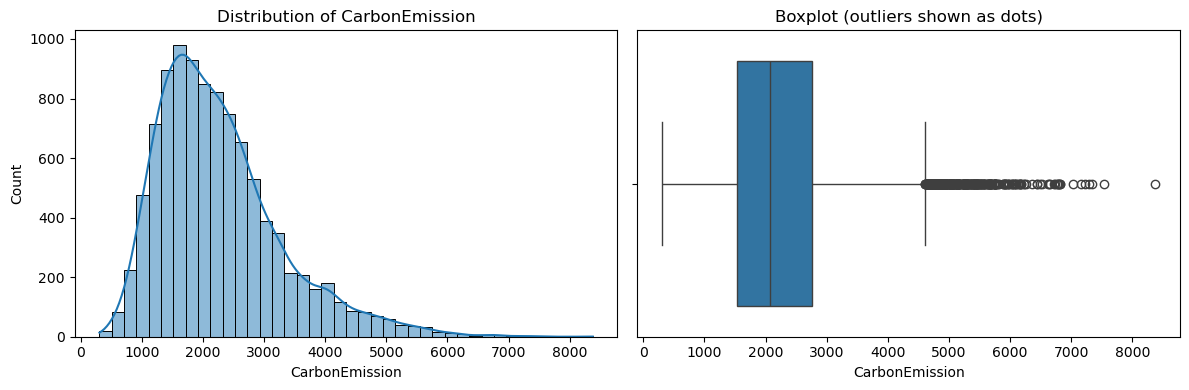

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Summary statistics of the target
print("=== CARBON EMISSION SUMMARY ===")
print(df["CarbonEmission"].describe().round(1))

# Skewness: 0 = symmetric, positive = long tail on the right
print(f"\nSkewness: {df['CarbonEmission'].skew():.2f}")

# Histogram + boxplot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["CarbonEmission"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of CarbonEmission")
sns.boxplot(x=df["CarbonEmission"], ax=axes[1])
axes[1].set_title("Boxplot (outliers shown as dots)")
plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: the target is right-skewed</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Numbers:</b> Mean 2,269 is above median 2,080; range 306 to 8,377</li><li><b>Meaning:</b> Most people emit a moderate amount, while a few heavy emitters pull the average up</li><li><b>Modelling impact:</b> Linear models can struggle with a long right tail (checked in Section 5)</li></ul></div>

=== NUMERIC SUMMARY ===
                                count    mean     std    min     25%     50%  \
Monthly_Grocery_Bill          10000.0   173.9    72.2   50.0   111.0   173.0   
Vehicle_Monthly_Distance_Km   10000.0  2031.5  2769.7    0.0    69.0   823.0   
Waste_Bag_Weekly_Count        10000.0     4.0     2.0    1.0     2.0     4.0   
How_Long_TV_PC_Daily_Hour     10000.0    12.1     7.1    0.0     6.0    12.0   
How_Many_New_Clothes_Monthly  10000.0    25.1    14.7    0.0    13.0    25.0   
How_Long_Internet_Daily_Hour  10000.0    11.9     7.3    0.0     6.0    12.0   
CarbonEmission                10000.0  2269.1  1017.7  306.0  1538.0  2080.0   

                                 75%     max  
Monthly_Grocery_Bill           237.0   299.0  
Vehicle_Monthly_Distance_Km   2516.8  9999.0  
Waste_Bag_Weekly_Count           6.0     7.0  
How_Long_TV_PC_Daily_Hour       18.0    24.0  
How_Many_New_Clothes_Monthly    38.0    50.0  
How_Long_Internet_Daily_Hour    18.0    24.0  
Carbon

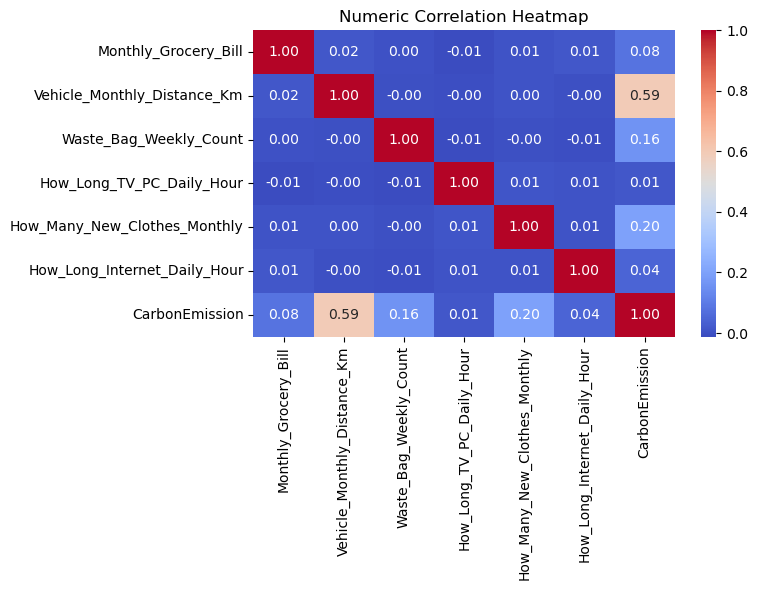

In [7]:
# Numeric columns only
num_cols = df.select_dtypes(include="number").columns

# Summary stats (look at min, max and the gap between mean and median)
print("=== NUMERIC SUMMARY ===")
print(df[num_cols].describe().round(1).T)

# Correlation of each numeric feature with the target
print("\n=== CORRELATION WITH CarbonEmission ===")
corr = df[num_cols].corr()["CarbonEmission"].drop("CarbonEmission")
print(corr.sort_values(ascending=False).round(3))

# Heatmap of all numeric correlations
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Numeric Correlation Heatmap")
plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: which numeric features move with emissions</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Strongest:</b> `Vehicle_Monthly_Distance_Km` r = 0.594</li><li><b>Moderate:</b> New clothes 0.199, waste bags 0.159</li><li><b>Almost none:</b> Grocery bill 0.082, internet hours 0.044, TV/PC hours 0.013</li><li><b>Caution:</b> Correlation only measures straight-line links between numbers. Categorical features are checked next</li></ul></div>

In [8]:
# Categorical columns except the list-style ones (handled later)
cat_cols = [c for c in df.select_dtypes(include="object").columns
            if c not in ["Recycling", "Cooking_With"]]

# Average emission per category, and the spread between best and worst group
print("=== AVG EMISSION BY CATEGORY (sorted) ===")
for col in cat_cols:
    means = df.groupby(col)["CarbonEmission"].mean().sort_values()
    print(f"\n{col}  (gap high-low: {means.max() - means.min():.0f})")
    print(means.round(0))

# Rank columns by how big the gap is
gaps = {c: df.groupby(c)["CarbonEmission"].mean().agg(lambda s: s.max() - s.min())
        for c in cat_cols}
print("\n=== RANKING BY GAP ===")
print(pd.Series(gaps).sort_values(ascending=False).round(0))

=== AVG EMISSION BY CATEGORY (sorted) ===

Body_Type  (gap high-low: 542)
Body_Type
underweight    2019.0
normal         2141.0
overweight     2359.0
obese          2561.0
Name: CarbonEmission, dtype: float64

Sex  (gap high-low: 334)
Sex
female    2103.0
male      2436.0
Name: CarbonEmission, dtype: float64

Diet  (gap high-low: 176)
Diet
vegan          2216.0
vegetarian     2217.0
pescatarian    2252.0
omnivore       2392.0
Name: CarbonEmission, dtype: float64

How_Often_Shower  (gap high-low: 67)
How_Often_Shower
daily              2238.0
less frequently    2247.0
more frequently    2287.0
twice a day        2305.0
Name: CarbonEmission, dtype: float64

Heating_Energy_Source  (gap high-low: 456)
Heating_Energy_Source
electricity    2039.0
natural gas    2248.0
wood           2297.0
coal           2495.0
Name: CarbonEmission, dtype: float64

Transport  (gap high-low: 1101)
Transport
walk/bicycle    1880.0
public          1966.0
private         2981.0
Name: CarbonEmission, dtype: float

<div style="border-left:6px solid #7c3aed;background:rgba(124,58,237,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#7c3aed;margin-bottom:6px">💡 Inference: categories ranked by gap between best and worst group</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Big drivers:</b> Vehicle type 1,867 (petrol about 3,750 vs electric about 1,883), air travel 1,310 (very frequently about 3,026 vs never about 1,716), transport 1,101</li><li><b>Medium:</b> Body type 542, heating 456 (coal highest, electricity lowest), waste bag size 390, sex 334</li><li><b>Weak:</b> Diet 176, social activity 138, showers 67, energy efficiency 35</li><li><b>Insight:</b> Electric-vehicle owners (1,883) emit about the same as people with no vehicle (1,922)</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 3</span><br><span style="font-size:21px;font-weight:700">Feature Engineering</span><br><span style="font-size:13px;opacity:.9">Binary flags, count features and composite scores</span></div>

In [9]:
import ast

# Convert the string "['Paper', 'Glass']" into a real Python list
df["Recycling"] = df["Recycling"].apply(ast.literal_eval)
df["Cooking_With"] = df["Cooking_With"].apply(ast.literal_eval)

# Binary flags for recycling materials (1 = recycles it, 0 = does not)
for item in ["Paper", "Plastic", "Glass", "Metal"]:
    df[f"Recycles_{item}"] = df["Recycling"].apply(lambda x: int(item in x))

# Binary flags for cooking appliances
for item in ["Stove", "Oven", "Microwave", "Grill", "Airfryer"]:
    df[f"Cooks_{item}"] = df["Cooking_With"].apply(lambda x: int(item in x))

# Count features: how many materials recycled / appliances used
df["Recycling_Count"] = df["Recycling"].apply(len)
df["Cooking_Appliance_Count"] = df["Cooking_With"].apply(len)

# Drop the original list columns (information is now in the flags)
df = df.drop(columns=["Recycling", "Cooking_With"])

# Check the new columns
new_cols = [c for c in df.columns if c.startswith(("Recycles_", "Cooks_"))] + \
           ["Recycling_Count", "Cooking_Appliance_Count"]
print(df[new_cols].head())
print("\nShape:", df.shape)

# Do these new features relate to emissions?
print("\n=== CORRELATION WITH CarbonEmission ===")
print(df[new_cols + ["CarbonEmission"]].corr()["CarbonEmission"]
      .drop("CarbonEmission").sort_values(ascending=False).round(3))

   Recycles_Paper  Recycles_Plastic  Recycles_Glass  Recycles_Metal  \
0               0                 0               0               1   
1               0                 0               0               1   
2               0                 0               0               1   
3               1                 1               1               1   
4               1                 0               0               0   

   Cooks_Stove  Cooks_Oven  Cooks_Microwave  Cooks_Grill  Cooks_Airfryer  \
0            1           1                0            0               0   
1            1           0                1            0               0   
2            0           1                1            0               0   
3            0           0                1            1               1   
4            0           1                0            0               0   

   Recycling_Count  Cooking_Appliance_Count  
0                1                        2  
1                1      

<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: list columns converted into 11 numeric features</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Created:</b> 4 recycling flags, 5 cooking flags, `Recycling_Count`, `Cooking_Appliance_Count`</li><li><b>Shape check:</b> 20 − 2 dropped + 11 new = 29 columns (matches the output)</li><li><b>Recycling:</b> Every recycling feature is negative; `Recycling_Count` is strongest (r = −0.119). More recycling goes with lower emissions</li><li><b>Cooking:</b> All cooking features are near zero (largest: oven 0.033), so appliances barely matter</li></ul></div>

In [10]:
# Total screen time = TV/PC hours + internet hours
df["Total_Screen_Time_Hours"] = (df["How_Long_TV_PC_Daily_Hour"]
                                 + df["How_Long_Internet_Daily_Hour"])

# Air travel: turn words into a score (never=0 ... very frequently=3)
air_map = {"never": 0, "rarely": 1, "frequently": 2, "very frequently": 3}
df["Air_Travel_Score"] = df["Frequency_of_Traveling_by_Air"].map(air_map)

# Waste volume: bag size score x number of bags per week
size_map = {"small": 1, "medium": 2, "large": 3, "extra large": 4}
df["Waste_Volume_Index"] = (df["Waste_Bag_Size"].map(size_map)
                            * df["Waste_Bag_Weekly_Count"])

# Lifestyle spend: groceries + clothes (simple sum, we'll scale later)
df["Lifestyle_Spend_Index"] = (df["Monthly_Grocery_Bill"]
                               + df["How_Many_New_Clothes_Monthly"])

# Check for accidental blanks from the mapping
new_feats = ["Total_Screen_Time_Hours", "Air_Travel_Score",
             "Waste_Volume_Index", "Lifestyle_Spend_Index"]
print("Missing values:\n", df[new_feats].isnull().sum())

# Summary and correlation with the target
print("\n", df[new_feats].describe().round(1).T)
print("\n=== CORRELATION WITH CarbonEmission ===")
print(df[new_feats + ["CarbonEmission"]].corr()["CarbonEmission"]
      .drop("CarbonEmission").sort_values(ascending=False).round(3))

Missing values:
 Total_Screen_Time_Hours    0
Air_Travel_Score           0
Waste_Volume_Index         0
Lifestyle_Spend_Index      0
dtype: int64

                            count   mean   std   min    25%    50%    75%  \
Total_Screen_Time_Hours  10000.0   24.0  10.2   0.0   17.0   24.0   31.0   
Air_Travel_Score         10000.0    1.5   1.1   0.0    1.0    2.0    3.0   
Waste_Volume_Index       10000.0   10.1   7.1   1.0    4.0    8.0   15.0   
Lifestyle_Spend_Index    10000.0  199.0  73.8  50.0  136.0  199.0  262.0   

                           max  
Total_Screen_Time_Hours   48.0  
Air_Travel_Score           3.0  
Waste_Volume_Index        28.0  
Lifestyle_Spend_Index    348.0  

=== CORRELATION WITH CarbonEmission ===
Air_Travel_Score           0.478
Waste_Volume_Index         0.223
Lifestyle_Spend_Index      0.119
Total_Screen_Time_Hours    0.040
Name: CarbonEmission, dtype: float64


<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: composite features</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Air_Travel_Score:</b> r = 0.478, second strongest numeric signal after distance</li><li><b>Waste_Volume_Index:</b> r = 0.223, better than waste count alone (0.159)</li><li><b>Lifestyle_Spend_Index:</b> r = 0.119, weaker than clothes alone (0.199), because groceries (50-299) swamp clothes (0-50)</li><li><b>Total_Screen_Time_Hours:</b> r = 0.040, almost no signal</li><li><b>Warning:</b> These scores overlap with the columns they were built from, which causes multicollinearity later (Section 5)</li></ul></div>

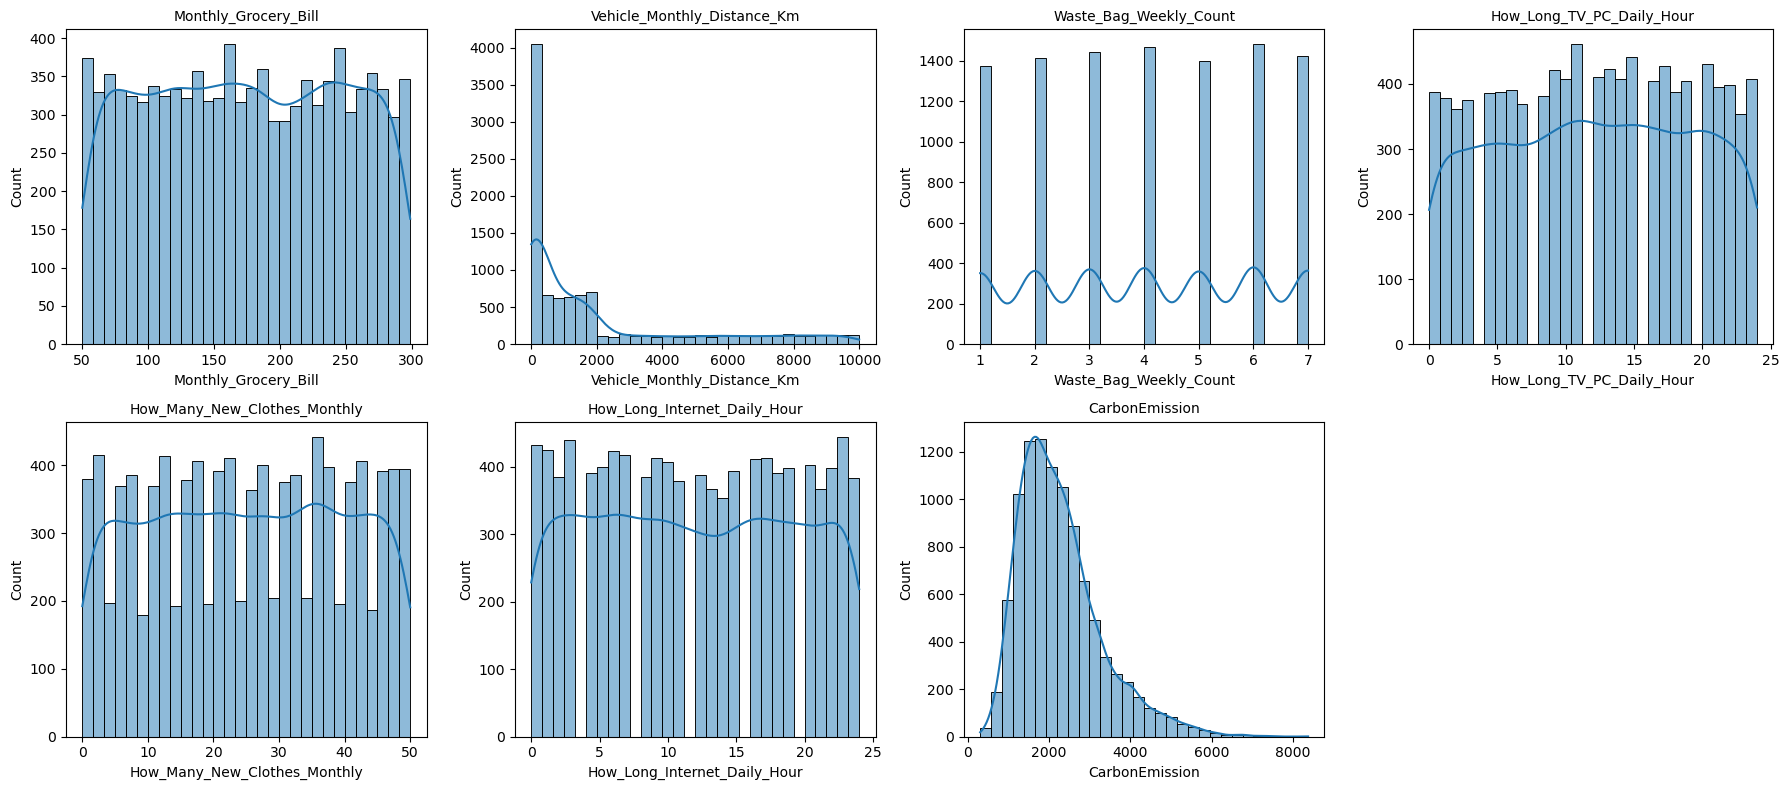

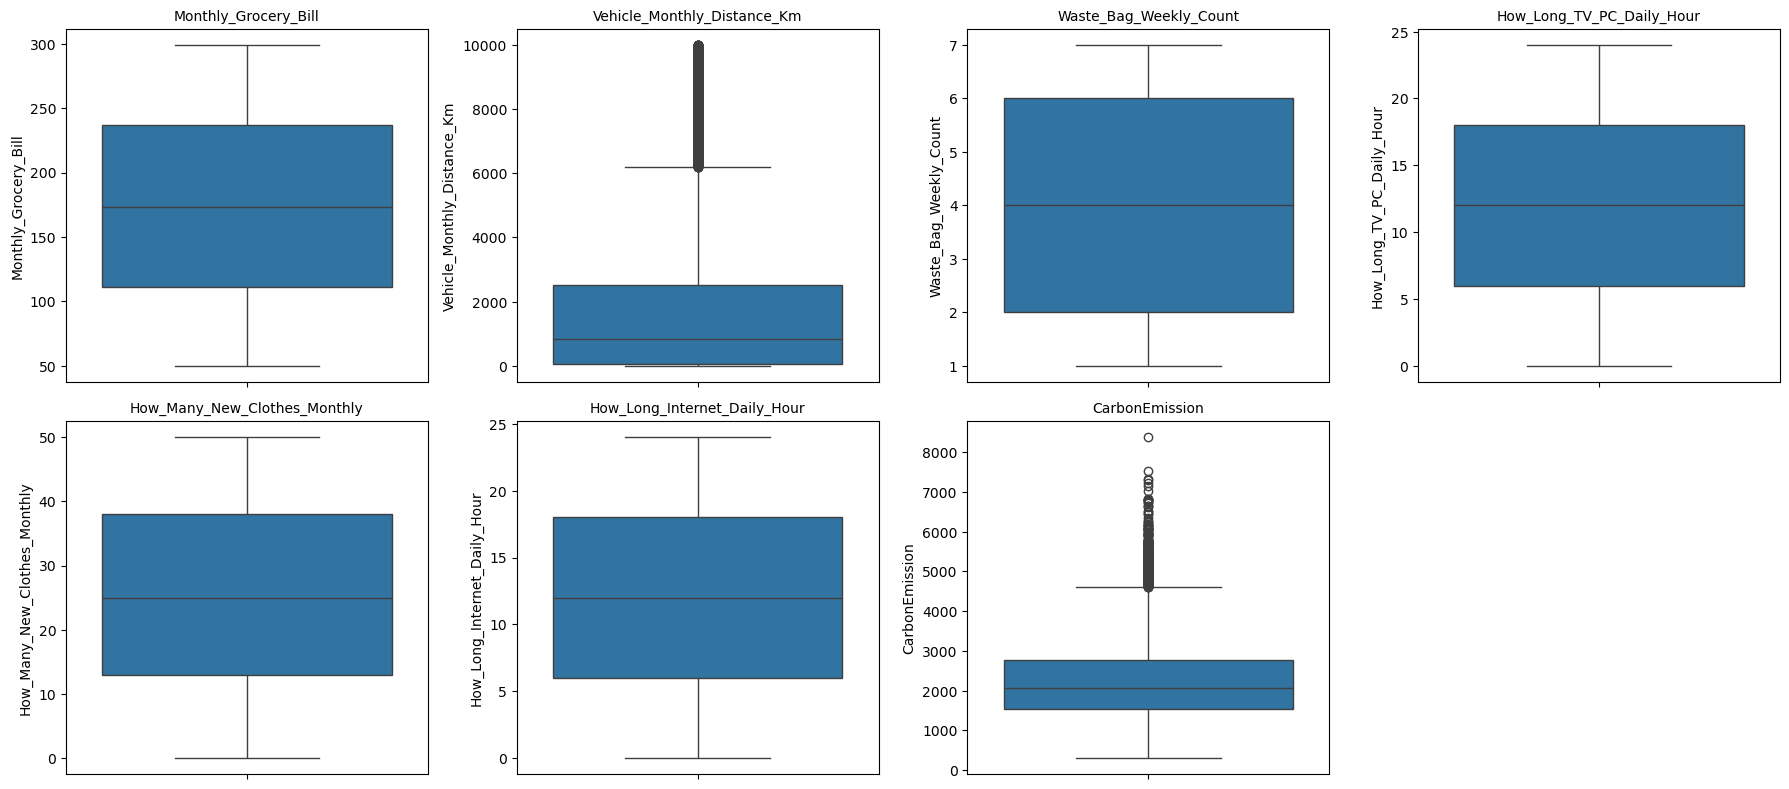

=== OUTLIER COUNT (IQR rule) ===
Monthly_Grocery_Bill                 0  (0.0%)
Vehicle_Monthly_Distance_Km       1294  (12.9%)
Waste_Bag_Weekly_Count               0  (0.0%)
How_Long_TV_PC_Daily_Hour            0  (0.0%)
How_Many_New_Clothes_Monthly         0  (0.0%)
How_Long_Internet_Daily_Hour         0  (0.0%)
CarbonEmission                     346  (3.5%)


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Original numeric columns plus the target
num_cols = ["Monthly_Grocery_Bill", "Vehicle_Monthly_Distance_Km",
            "Waste_Bag_Weekly_Count", "How_Long_TV_PC_Daily_Hour",
            "How_Many_New_Clothes_Monthly", "How_Long_Internet_Daily_Hour",
            "CarbonEmission"]

# Histograms: shape of each column
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col, fontsize=10)
axes.ravel()[-1].axis("off")  # hide the unused panel
plt.tight_layout()
plt.show()

# Boxplots: spot outliers
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col, fontsize=10)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# Count outliers with the IQR rule (beyond 1.5 x IQR from the box)
print("=== OUTLIER COUNT (IQR rule) ===")
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:32s} {n_out:5d}  ({n_out / len(df) * 100:.1f}%)")

<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: distributions and outliers</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Uniform-looking:</b> Grocery bill, TV/PC hours, clothes and internet hours are roughly flat. Values are equally common and there are 0 outliers</li><li><b>Waste count:</b> 7 equal bars for whole numbers 1 to 7</li><li><b>Distance:</b> About 4,000 people sit near 0 km, with a long tail to 10,000 km. 1,294 outliers (12.9%)</li><li><b>Target:</b> Right-skewed hill; 346 outliers (3.5%)</li></ul></div>

<div style="border-left:6px solid #7c3aed;background:rgba(124,58,237,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#7c3aed;margin-bottom:6px">💡 Decision: keep all outliers</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Why:</b> 12.9% is far too many to be typos. They are real long-distance drivers, and exactly the people who emit the most</li><li><b>Handling:</b> No deletion. Tree models cope with them; for linear models we monitor residuals</li></ul></div>

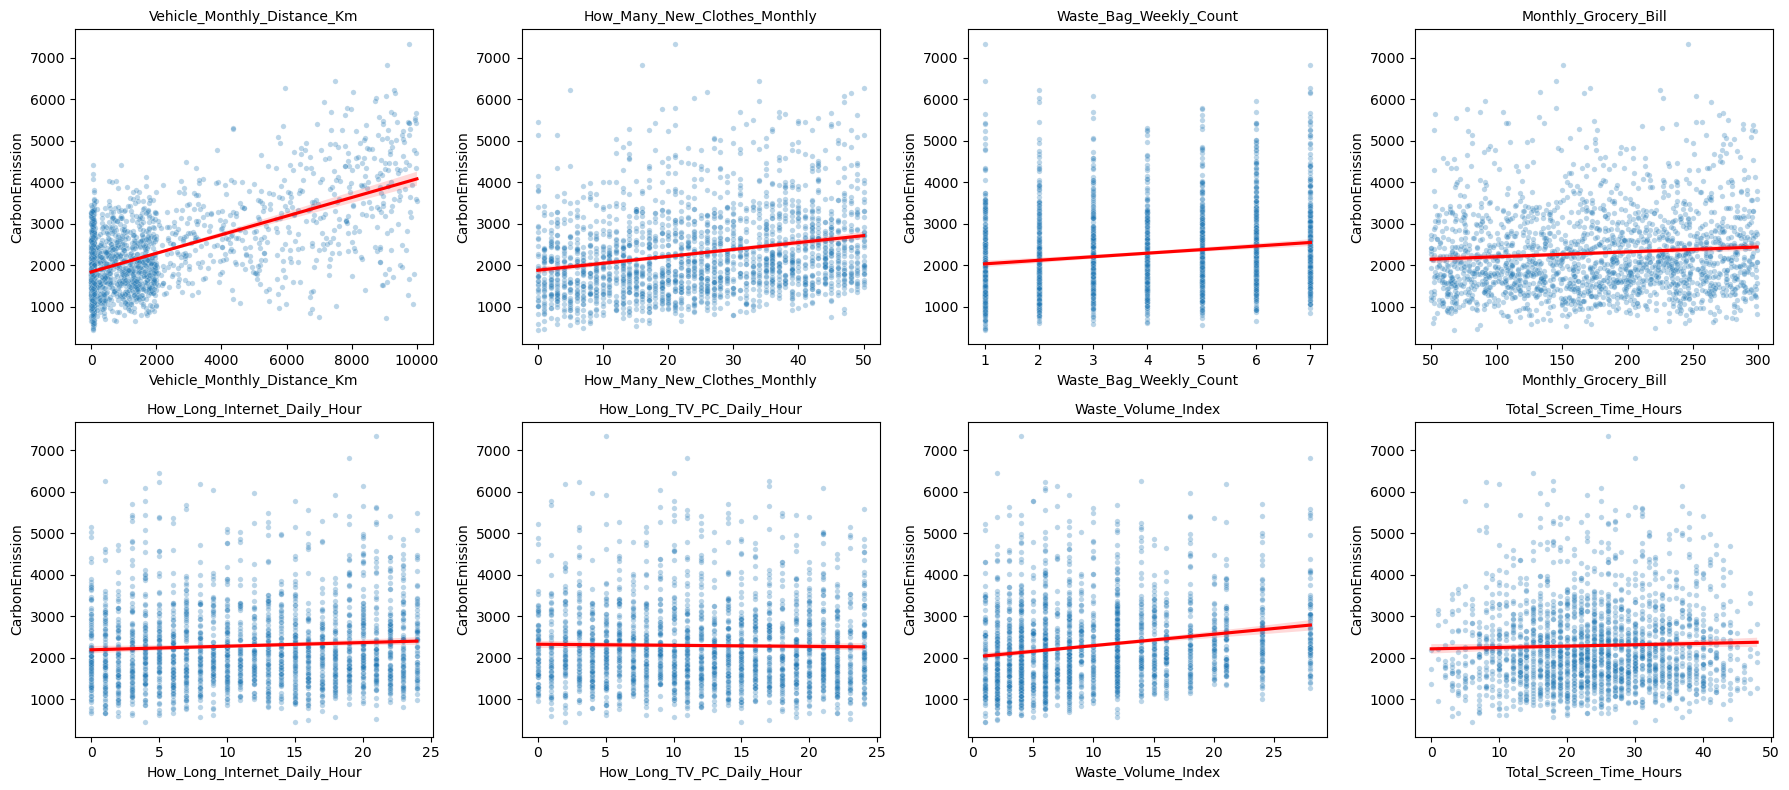

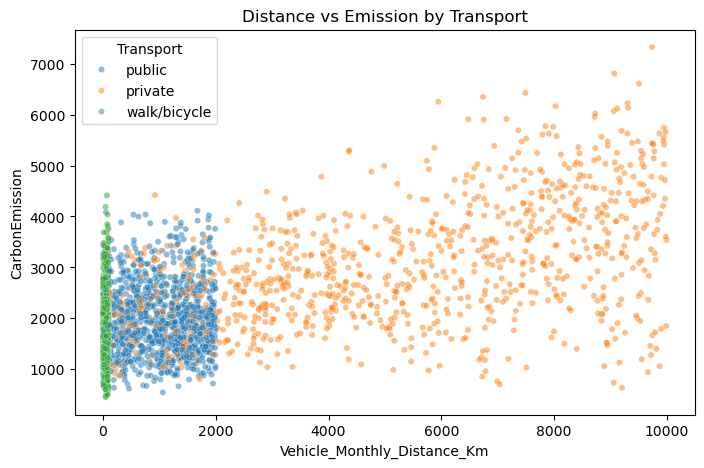

In [14]:
# Features to compare against the target (original + engineered)
feats = ["Vehicle_Monthly_Distance_Km", "How_Many_New_Clothes_Monthly",
         "Waste_Bag_Weekly_Count", "Monthly_Grocery_Bill",
         "How_Long_Internet_Daily_Hour", "How_Long_TV_PC_Daily_Hour",
         "Waste_Volume_Index", "Total_Screen_Time_Hours"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), feats):
    # Sample 2,000 points so the plot stays readable
    sample = df.sample(2000, random_state=42)
    sns.scatterplot(data=sample, x=col, y="CarbonEmission", alpha=0.3, s=15, ax=ax)
    # Red trend line
    sns.regplot(data=sample, x=col, y="CarbonEmission", scatter=False,
                color="red", ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

# Distance vs emissions, colored by Transport type
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(3000, random_state=42),
                x="Vehicle_Monthly_Distance_Km", y="CarbonEmission",
                hue="Transport", alpha=0.5, s=20)
plt.title("Distance vs Emission by Transport")
plt.show()

<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: numeric features vs emissions</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Distance:</b> Clear upward slope, from about 1,800 at 0 km to about 4,000 at 10,000 km</li><li><b>Fan shape:</b> Spread widens at high distance: a first sign of unequal variance (heteroscedasticity)</li><li><b>Mild slopes:</b> Clothes, waste count and Waste_Volume_Index</li><li><b>Flat:</b> Grocery bill, internet, TV/PC and total screen time have no visible link</li><li><b>Meaning:</b> Even for distance the cloud is wide, so other factors (fuel type, flying) explain the rest</li></ul></div>

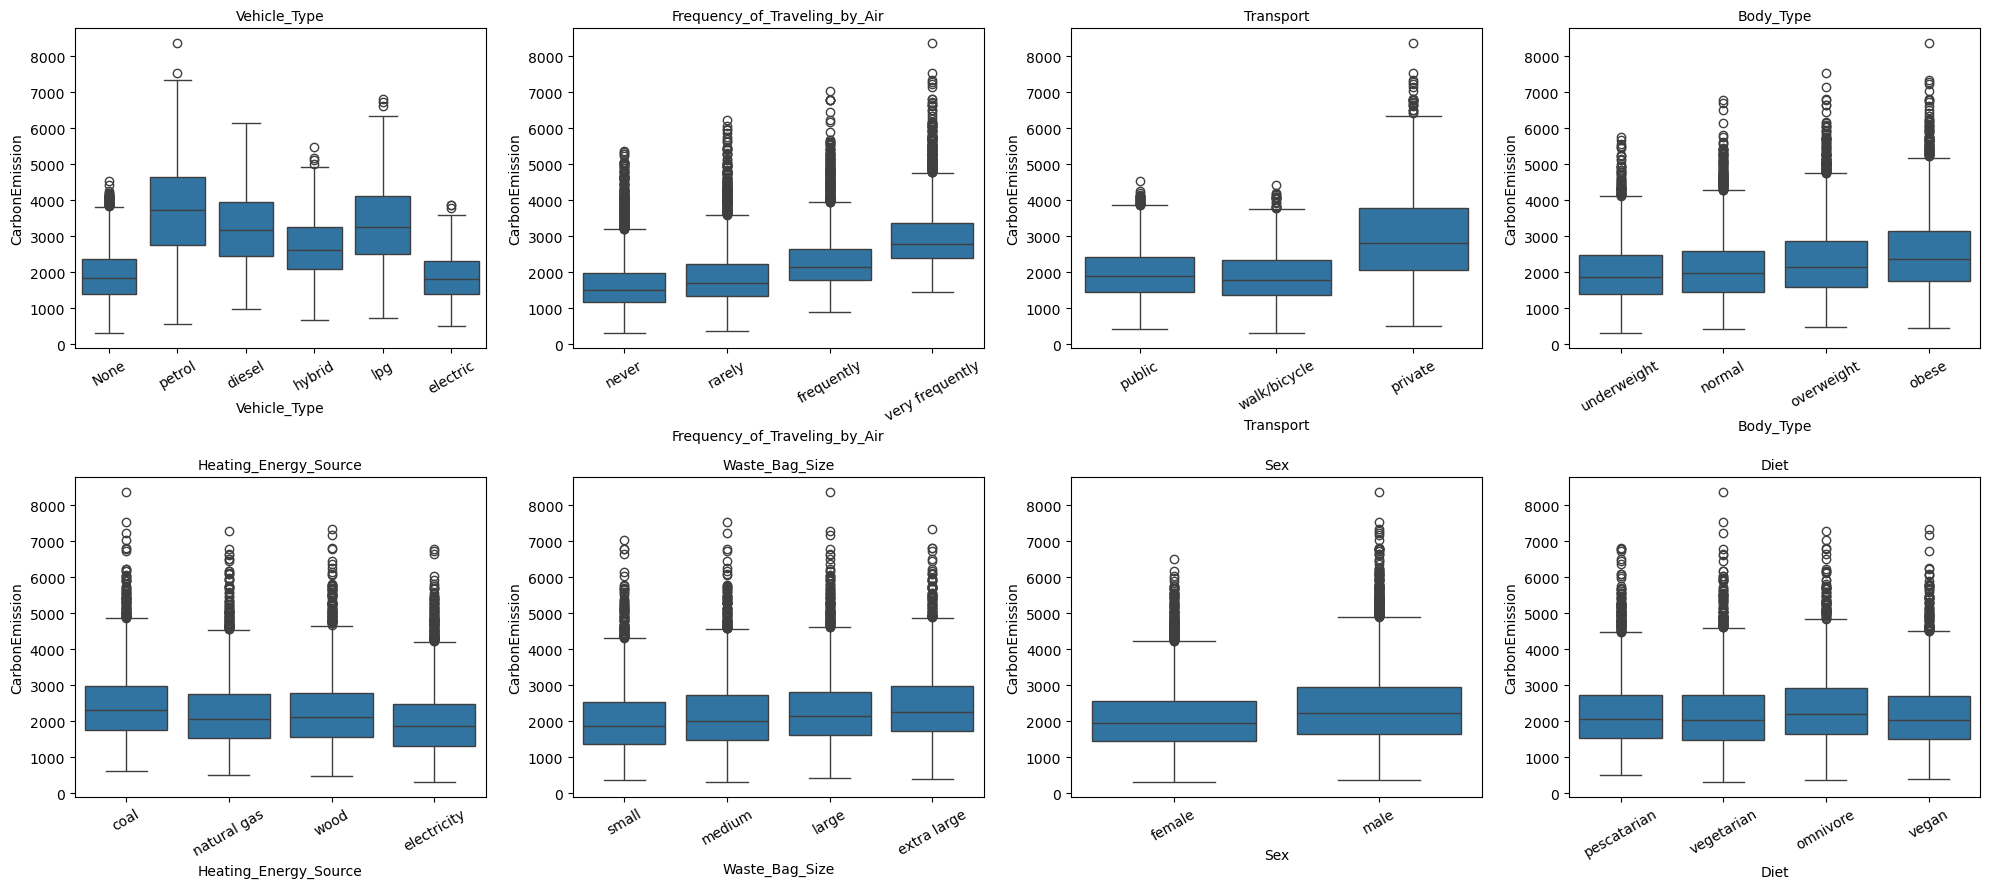

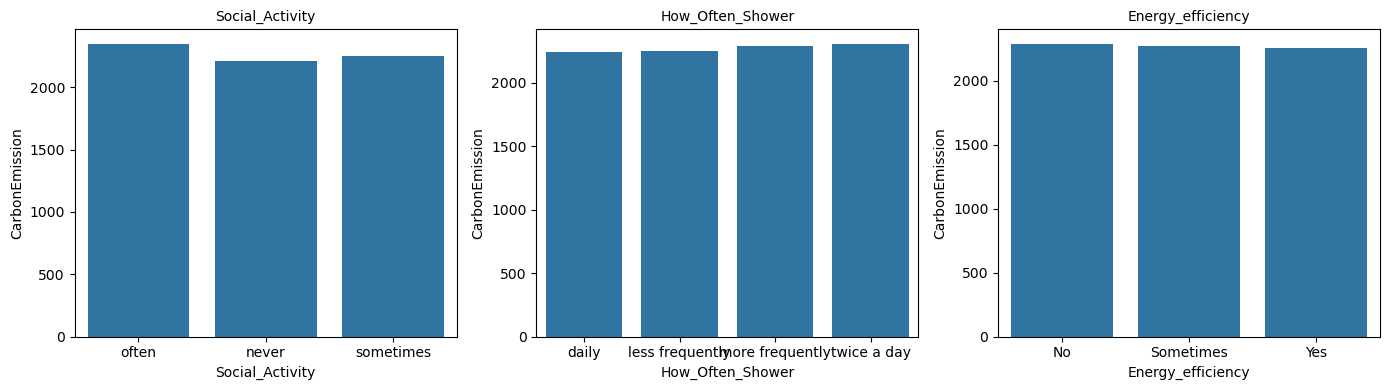

In [15]:
# Most important categorical columns from Step 7
cat_plot = ["Vehicle_Type", "Frequency_of_Traveling_by_Air", "Transport",
            "Body_Type", "Heating_Energy_Source", "Waste_Bag_Size",
            "Sex", "Diet"]

# Order for ordinal columns so the chart reads naturally
orders = {
    "Frequency_of_Traveling_by_Air": ["never", "rarely", "frequently", "very frequently"],
    "Waste_Bag_Size": ["small", "medium", "large", "extra large"],
    "Body_Type": ["underweight", "normal", "overweight", "obese"],
}

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_plot):
    sns.boxplot(data=df, x=col, y="CarbonEmission",
                order=orders.get(col), ax=ax)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

# Bonus: average emission as a bar chart for the three weakest columns
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Social_Activity", "How_Often_Shower", "Energy_efficiency"]):
    sns.barplot(data=df, x=col, y="CarbonEmission", errorbar=None, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: categories vs emissions</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Vehicle type:</b> Petrol box is highest and widest; electric and None are lowest and nearly identical</li><li><b>Air travel:</b> Clean staircase: never < rarely < frequently < very frequently</li><li><b>Transport:</b> Private is far above public and walk/bicycle, which look alike</li><li><b>Weak columns:</b> Social activity, shower frequency and energy efficiency bars are nearly the same height</li><li><b>Caution:</b> Boxes overlap heavily, so no single feature predicts emissions alone; the model needs them together</li></ul></div>

=== TOP 10 FEATURES BY |CORRELATION| WITH TARGET ===
Vehicle_Monthly_Distance_Km     0.594
Air_Travel_Score                0.478
Waste_Volume_Index              0.223
How_Many_New_Clothes_Monthly    0.199
Waste_Bag_Weekly_Count          0.159
Lifestyle_Spend_Index           0.119
Recycling_Count                -0.119
Monthly_Grocery_Bill            0.082
Recycles_Paper                 -0.080
Recycles_Metal                 -0.069
Name: CarbonEmission, dtype: float64


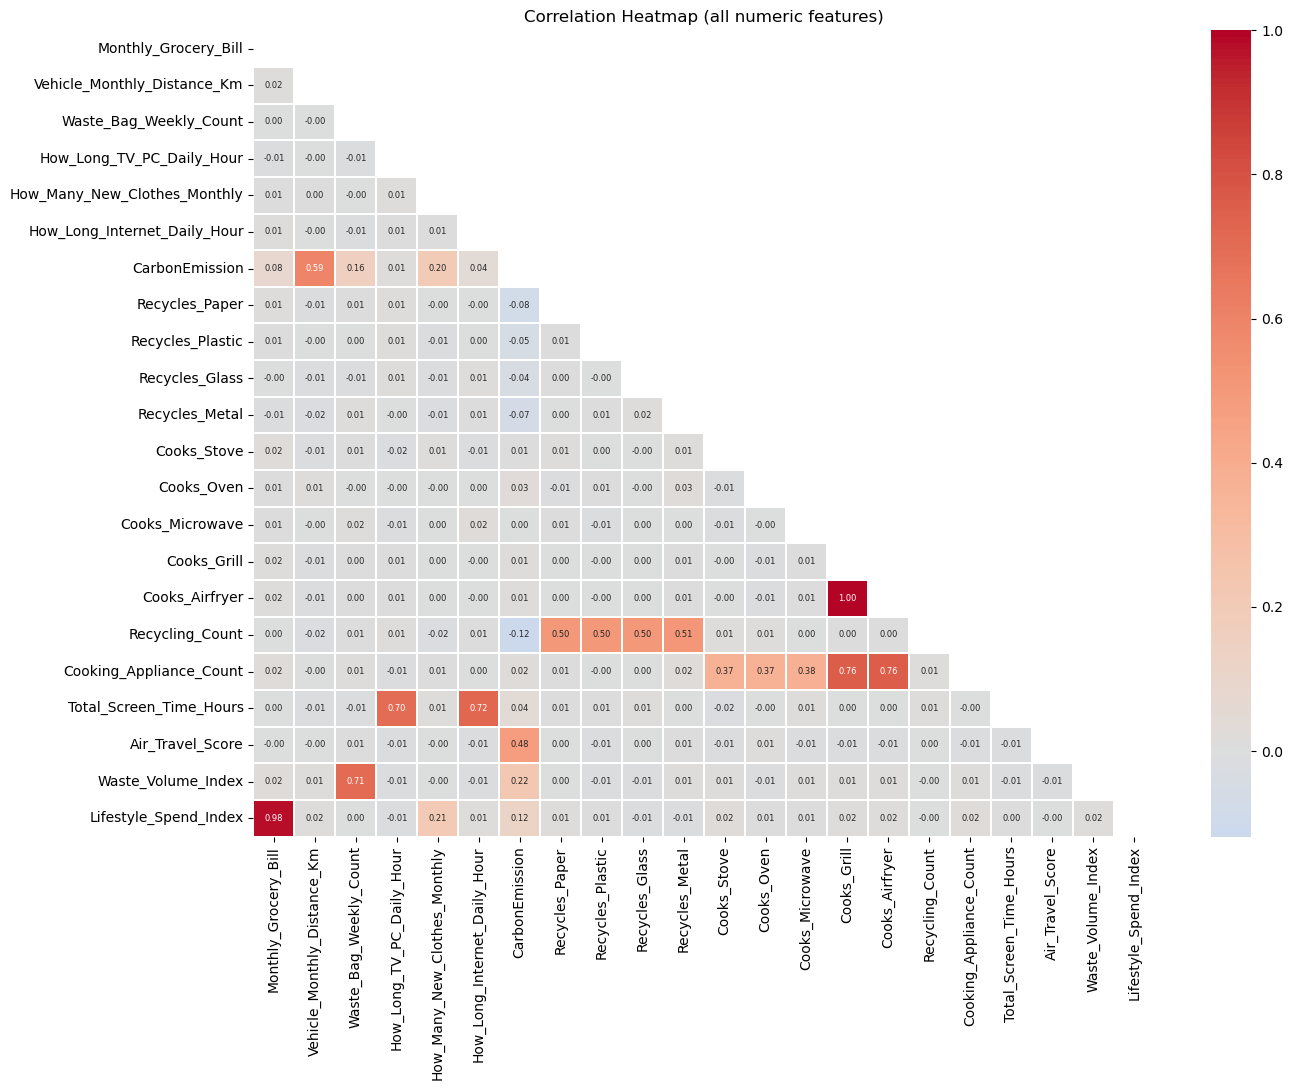


=== HIGHLY CORRELATED FEATURE PAIRS (|r| > 0.7) ===
Cooks_Airfryer           Cooks_Grill                     1.000
Lifestyle_Spend_Index    Monthly_Grocery_Bill            0.980
Cooking_Appliance_Count  Cooks_Grill                     0.757
                         Cooks_Airfryer                  0.757
Total_Screen_Time_Hours  How_Long_Internet_Daily_Hour    0.718
Waste_Volume_Index       Waste_Bag_Weekly_Count          0.707
Total_Screen_Time_Hours  How_Long_TV_PC_Daily_Hour       0.701
dtype: float64


In [19]:
# All numeric columns (original + engineered + flags)
num_all = df.select_dtypes(include="number").columns

# Top 10 correlations with the target (absolute value)
corr_target = (df[num_all].corr()["CarbonEmission"]
               .drop("CarbonEmission")
               .sort_values(key=abs, ascending=False))
print("=== TOP 10 FEATURES BY |CORRELATION| WITH TARGET ===")
print(corr_target.head(10).round(3))

# Full heatmap (lower triangle only, to keep it readable)
import numpy as np
corr = df[num_all].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(14,11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 6},
            linewidths=0.3)
plt.title("Correlation Heatmap (all numeric features)")
plt.tight_layout()
plt.show()

# Pairs of features that are very similar (|r| > 0.7), excluding the target
pairs = corr.where(~mask).stack()
pairs = pairs[(pairs.abs() > 0.7)]
pairs = pairs.drop(labels=[i for i in pairs.index if "CarbonEmission" in i])
print("\n=== HIGHLY CORRELATED FEATURE PAIRS (|r| > 0.7) ===")
print(pairs.sort_values(ascending=False).round(3))

<div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Inference: correlation heatmap shows engineered duplicates</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Healthy:</b> Original features are almost uncorrelated with each other (squares near 0), so each brings its own information</li><li><b>Copies:</b> `Cooks_Grill` and `Cooks_Airfryer` r = 1.00; `Lifestyle_Spend_Index` and grocery bill r = 0.98</li><li><b>Sums:</b> Count and total features correlate 0.70-0.76 with the parts they were built from</li><li><b>Plan:</b> Keep all for tree models; remove duplicates for linear models (VIF step)</li></ul></div>

<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ EDA summary</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Top drivers:</b> Vehicle distance, air travel, vehicle fuel type</li><li><b>Secondary:</b> Heating source, body type, waste volume, clothes, sex</li><li><b>Weak:</b> Diet, showers, energy efficiency, social activity, cooking appliances</li><li><b>Data quality:</b> Clean; outliers kept; blanks understood</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 4</span><br><span style="font-size:21px;font-weight:700">Train-Test Split & Preprocessing</span><br><span style="font-size:13px;opacity:.9">Split first, then impute, scale and one-hot encode using training data only</span></div>

In [20]:
from sklearn.model_selection import train_test_split

# Separate the target (y) from the clues (X)
X = df.drop(columns=["CarbonEmission"])
y = df["CarbonEmission"]

# 80% train, 20% test (random_state makes it repeatable)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Check sizes
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

# Make sure both sets look similar (mean/std of the target)
print("\nTrain target mean/std:", round(y_train.mean(), 1), round(y_train.std(), 1))
print("Test target mean/std: ", round(y_test.mean(), 1), round(y_test.std(), 1))

X_train: (8000, 32) | X_test: (2000, 32)
y_train: (8000,) | y_test: (2000,)

Train target mean/std: 2263.6 1017.1
Test target mean/std:  2291.5 1019.9


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: fair split</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Sizes:</b> 8,000 train, 2,000 test; 32 features</li><li><b>Balance:</b> Target mean 2,263.6 (train) vs 2,291.5 (test); std 1,017 vs 1,020</li><li><b>Why split first:</b> Scaling or imputing before the split would leak test information into training</li></ul></div>

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Split columns by type
num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(include="object").columns.tolist()
print("Numeric:", len(num_features), "| Categorical:", len(cat_features))

# Recipe for numbers: fill blanks (median) -> scale
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Recipe for text: fill blanks (most common) -> one-hot (drop first avoids duplicates)
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore",
                             sparse_output=False)),
])

# Combine both recipes
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_features),
    ("cat", cat_pipe, cat_features),
])

# Learn from TRAIN only, then apply to both
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

# Get readable names for the final columns
feature_names = preprocessor.get_feature_names_out()

# Sanity checks
print("\nTrain shape after:", X_train_p.shape)
print("Test shape after: ", X_test_p.shape)
print("NaNs in train/test:", np.isnan(X_train_p).sum(), np.isnan(X_test_p).sum())
print("\nFirst 5 new column names:", list(feature_names[:5]))
print("Last 5 new column names: ", list(feature_names[-5:]))

# Scaled numeric columns should have mean ~0 and std ~1 on TRAIN
print("\nMean of first 3 scaled cols:", X_train_p[:, :3].mean(axis=0).round(3))
print("Std of first 3 scaled cols: ", X_train_p[:, :3].std(axis=0).round(3))

Numeric: 21 | Categorical: 11

Train shape after: (8000, 51)
Test shape after:  (2000, 51)
NaNs in train/test: 0 0

First 5 new column names: ['num__Monthly_Grocery_Bill', 'num__Vehicle_Monthly_Distance_Km', 'num__Waste_Bag_Weekly_Count', 'num__How_Long_TV_PC_Daily_Hour', 'num__How_Many_New_Clothes_Monthly']
Last 5 new column names:  ['cat__Waste_Bag_Size_large', 'cat__Waste_Bag_Size_medium', 'cat__Waste_Bag_Size_small', 'cat__Energy_efficiency_Sometimes', 'cat__Energy_efficiency_Yes']

Mean of first 3 scaled cols: [ 0. -0. -0.]
Std of first 3 scaled cols:  [1. 1. 1.]


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: pipeline works with no leakage</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Columns:</b> 21 numeric + 11 categorical = 32 features, expanding to 51 columns after one-hot encoding</li><li><b>Checks:</b> 0 missing values; scaled columns have mean 0 and standard deviation 1</li><li><b>Note:</b> Fitted on train only, then applied to test</li><li><b>Watch out:</b> Some columns are exact copies or sums of others; this is investigated with VIF</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 5</span><br><span style="font-size:21px;font-weight:700">Baseline Linear Regression & Diagnostics</span><br><span style="font-size:13px;opacity:.9">Fit the baseline, then test linearity, equal spread, normality, independence and multicollinearity</span></div>

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Train the baseline model
lr = LinearRegression()
lr.fit(X_train_p, y_train)

# Predict on both sets
pred_train = lr.predict(X_train_p)
pred_test = lr.predict(X_test_p)

# Helper that returns all four scores
def evaluate(y_true, y_pred, n_features):
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return {"R2": r2, "Adj_R2": adj_r2, "RMSE": rmse, "MAE": mae}

k = X_train_p.shape[1]
results = pd.DataFrame({
    "Train": evaluate(y_train, pred_train, k),
    "Test": evaluate(y_test, pred_test, k),
}).round(3)
print("=== BASELINE LINEAR REGRESSION ===")
print(results)

# Context: how big is the typical error compared to the average emission?
print(f"\nTest RMSE as % of mean emission: "
      f"{results.loc['RMSE', 'Test'] / y_test.mean() * 100:.1f}%")

=== BASELINE LINEAR REGRESSION ===
          Train     Test
R2        0.938    0.938
Adj_R2    0.938    0.937
RMSE    252.373  253.475
MAE     163.155  164.942

Test RMSE as % of mean emission: 11.1%


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: strong baseline</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Test scores:</b> R² 0.938, Adj R² 0.937, RMSE 253.5, MAE 164.9</li><li><b>Overfitting:</b> None: train and test are almost identical (0.938 vs 0.938)</li><li><b>Error size:</b> RMSE is about 11% of the mean emission; RMSE > MAE signals a few large misses on heavy emitters</li></ul></div>

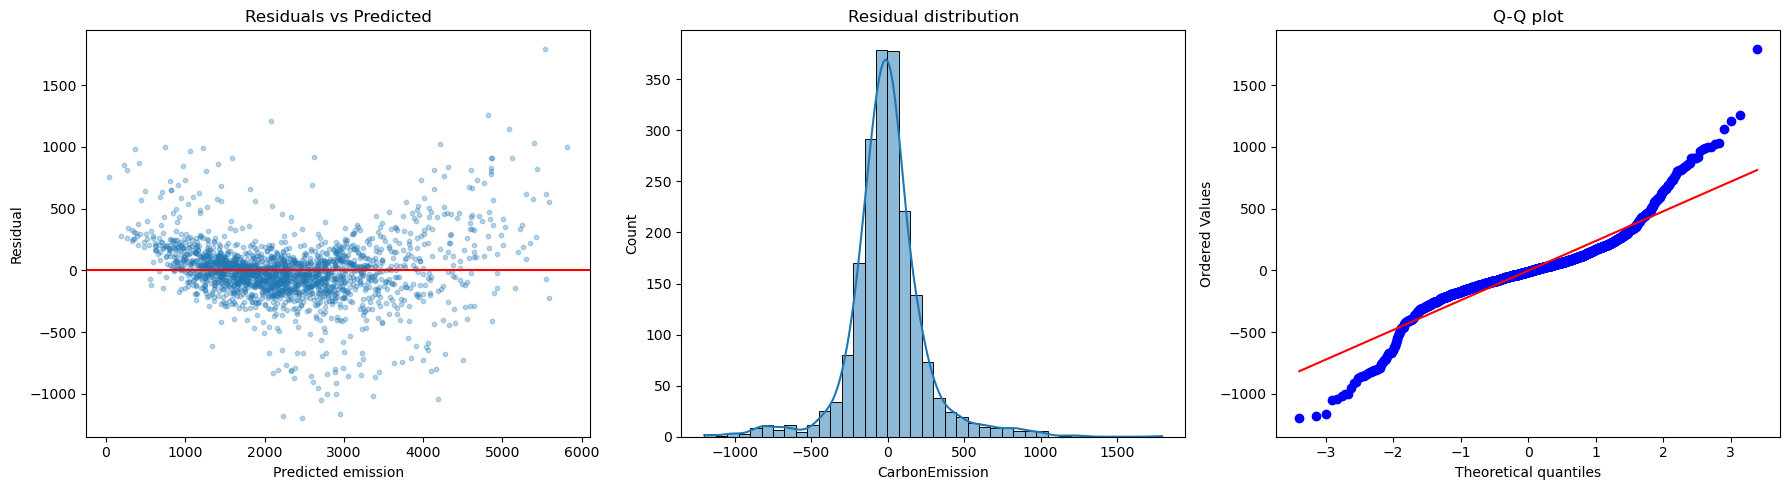

Mean residual: -2.32  (should be near 0)
Residual skewness: 0.31  (0 = symmetric)
Residual kurtosis: 5.64  (0 = normal tails)


In [23]:
import scipy.stats as stats

# Residuals = actual - predicted (on the test set)
resid = y_test - pred_test

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Residuals vs predicted (linearity + equal spread)
axes[0].scatter(pred_test, resid, alpha=0.3, s=10)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicted emission")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")

# 2) Histogram of residuals (should look like a bell)
sns.histplot(resid, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")

# 3) Q-Q plot (dots should hug the red line if normal)
stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot")

plt.tight_layout()
plt.show()

# Quick numbers
print(f"Mean residual: {resid.mean():.2f}  (should be near 0)")
print(f"Residual skewness: {stats.skew(resid):.2f}  (0 = symmetric)")
print(f"Residual kurtosis: {stats.kurtosis(resid):.2f}  (0 = normal tails)")

<div style="border-left:6px solid #dc2626;background:rgba(220,38,38,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#dc2626;margin-bottom:6px">❌ Inference: residual plots show assumption problems</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Mean residual:</b> −2.3, so no overall bias</li><li><b>Linearity:</b> Residuals form a smile (U) shape against predictions: the line misses a curve</li><li><b>Equal spread:</b> Spread widens for high predictions (funnel)</li><li><b>Normality:</b> Kurtosis 5.64 and S-shaped Q-Q plot show heavy tails</li><li><b>Likely cause:</b> Effects multiply (e.g. distance x fuel type) while the model adds them</li></ul></div>

In [24]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Add an intercept column for statsmodels
X_sm = sm.add_constant(X_train_p)
resid_train = y_train.values - pred_train

# 1) Homoscedasticity (Breusch-Pagan)
bp_stat, bp_p, _, _ = het_breuschpagan(resid_train, X_sm)
print(f"Breusch-Pagan p-value: {bp_p:.4g}  (p<0.05 -> unequal spread)")

# 2) Normality (Jarque-Bera, works well for large samples)
jb_stat, jb_p = stats.jarque_bera(resid_train)
print(f"Jarque-Bera p-value:   {jb_p:.4g}  (p<0.05 -> not normal)")

# 3) Independence of errors (Durbin-Watson)
print(f"Durbin-Watson:         {durbin_watson(resid_train):.2f}  (about 2 = fine)")

# 4) Multicollinearity: VIF for every processed feature
vif = pd.DataFrame({
    "feature": feature_names,
    "VIF": [variance_inflation_factor(X_train_p, i) for i in range(X_train_p.shape[1])],
})
vif["VIF"] = vif["VIF"].replace(np.inf, 9999).round(1)
vif = vif.sort_values("VIF", ascending=False)
print("\n=== TOP 15 VIF VALUES ===")
print(vif.head(15).to_string(index=False))
print(f"\nFeatures with VIF > 10: {(vif['VIF'] > 10).sum()}")

Breusch-Pagan p-value: 0  (p<0.05 -> unequal spread)
Jarque-Bera p-value:   0  (p<0.05 -> not normal)
Durbin-Watson:         2.01  (about 2 = fine)


C:\Users\nazmi\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)



=== TOP 15 VIF VALUES ===
                          feature    VIF
        num__Monthly_Grocery_Bill 9999.0
num__How_Many_New_Clothes_Monthly 9999.0
   num__How_Long_TV_PC_Daily_Hour 9999.0
                  num__Cooks_Oven 9999.0
             num__Cooks_Microwave 9999.0
num__How_Long_Internet_Daily_Hour 9999.0
              num__Recycles_Paper 9999.0
            num__Recycles_Plastic 9999.0
              num__Recycles_Glass 9999.0
              num__Recycles_Metal 9999.0
                 num__Cooks_Stove 9999.0
             num__Recycling_Count 9999.0
     num__Cooking_Appliance_Count 9999.0
                 num__Cooks_Grill 9999.0
              num__Cooks_Airfryer 9999.0

Features with VIF > 10: 29


<div style="border-left:6px solid #dc2626;background:rgba(220,38,38,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#dc2626;margin-bottom:6px">❌ Inference: formal tests confirm the plots</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Breusch-Pagan:</b> p ≈ 0: unequal spread is real</li><li><b>Jarque-Bera:</b> p ≈ 0: residuals are not normal</li><li><b>Durbin-Watson:</b> 2.01: errors are independent (this check passes)</li><li><b>VIF:</b> 29 features above 10, many infinite. They are exact copies or sums of other columns</li><li><b>Consequence:</b> Predictions are fine, but coefficients and p-values would be unreliable</li></ul></div>

In [25]:
# Columns to drop for the linear models only
drop_cols = ["Lifestyle_Spend_Index", "Total_Screen_Time_Hours",
             "Recycling_Count", "Cooking_Appliance_Count", "Cooks_Airfryer"]

X_train_l = X_train.drop(columns=drop_cols)
X_test_l = X_test.drop(columns=drop_cols)

# Rebuild the preprocessor on the reduced feature set
num_l = X_train_l.select_dtypes(include="number").columns.tolist()
cat_l = X_train_l.select_dtypes(include="object").columns.tolist()

preprocessor_l = ColumnTransformer([
    ("num", num_pipe, num_l),
    ("cat", cat_pipe, cat_l),
])
X_train_lp = preprocessor_l.fit_transform(X_train_l)
X_test_lp = preprocessor_l.transform(X_test_l)
names_l = preprocessor_l.get_feature_names_out()
print("New shape:", X_train_lp.shape)

# Retrain linear regression and compare scores
lr2 = LinearRegression().fit(X_train_lp, y_train)
k2 = X_train_lp.shape[1]
res2 = pd.DataFrame({
    "Train": evaluate(y_train, lr2.predict(X_train_lp), k2),
    "Test": evaluate(y_test, lr2.predict(X_test_lp), k2),
}).round(3)
print("\n=== LINEAR REGRESSION (redundant features removed) ===")
print(res2)

# Re-check VIF
vif2 = pd.DataFrame({
    "feature": names_l,
    "VIF": [variance_inflation_factor(X_train_lp, i) for i in range(k2)],
}).sort_values("VIF", ascending=False)
vif2["VIF"] = vif2["VIF"].round(2)
print("\n=== TOP 10 VIF (after cleanup) ===")
print(vif2.head(10).to_string(index=False))
print(f"\nFeatures with VIF > 5: {(vif2['VIF'] > 5).sum()}")

New shape: (8000, 46)

=== LINEAR REGRESSION (redundant features removed) ===
          Train     Test
R2        0.938    0.938
Adj_R2    0.938    0.937
RMSE    252.373  253.475
MAE     163.155  164.942


C:\Users\nazmi\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)



=== TOP 10 VIF (after cleanup) ===
                                           feature  VIF
                        cat__Vehicle_Type_electric  inf
                          cat__Vehicle_Type_hybrid  inf
                             cat__Vehicle_Type_lpg  inf
                       cat__Transport_walk/bicycle  inf
         cat__Frequency_of_Traveling_by_Air_rarely  inf
          cat__Frequency_of_Traveling_by_Air_never  inf
cat__Frequency_of_Traveling_by_Air_very frequently  inf
                          cat__Vehicle_Type_diesel  inf
                             cat__Transport_public  inf
                             num__Air_Travel_Score  inf

Features with VIF > 5: 14


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: summary columns removed at no cost</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Dropped:</b> Lifestyle_Spend_Index, Total_Screen_Time_Hours, Recycling_Count, Cooking_Appliance_Count, Cooks_Airfryer</li><li><b>Proof they were duplicates:</b> Scores unchanged (R² 0.938, RMSE 253.475); columns 51 → 46</li><li><b>Remaining:</b> Infinite VIF persists for air travel and transport/vehicle-type blocks</li></ul></div>

In [26]:
# Drop the text columns that duplicate other features
drop_more = ["Frequency_of_Traveling_by_Air", "Transport"]
X_train_l2 = X_train_l.drop(columns=drop_more)
X_test_l2 = X_test_l.drop(columns=drop_more)

# Rebuild the preprocessor on the cleaned set
num_l2 = X_train_l2.select_dtypes(include="number").columns.tolist()
cat_l2 = X_train_l2.select_dtypes(include="object").columns.tolist()
preprocessor_l2 = ColumnTransformer([
    ("num", num_pipe, num_l2),
    ("cat", cat_pipe, cat_l2),
])
X_train_lp2 = preprocessor_l2.fit_transform(X_train_l2)
X_test_lp2 = preprocessor_l2.transform(X_test_l2)
names_l2 = preprocessor_l2.get_feature_names_out()
print("New shape:", X_train_lp2.shape)

# Retrain and score
lr3 = LinearRegression().fit(X_train_lp2, y_train)
k3 = X_train_lp2.shape[1]
res3 = pd.DataFrame({
    "Train": evaluate(y_train, lr3.predict(X_train_lp2), k3),
    "Test": evaluate(y_test, lr3.predict(X_test_lp2), k3),
}).round(3)
print("\n=== LINEAR REGRESSION (clean features) ===")
print(res3)

# Re-check VIF
vif3 = pd.DataFrame({
    "feature": names_l2,
    "VIF": [variance_inflation_factor(X_train_lp2, i) for i in range(k3)],
}).sort_values("VIF", ascending=False)
vif3["VIF"] = vif3["VIF"].round(2)
print("\n=== TOP 10 VIF (clean) ===")
print(vif3.head(10).to_string(index=False))
print(f"\nFeatures with VIF > 5: {(vif3['VIF'] > 5).sum()}")

New shape: (8000, 41)

=== LINEAR REGRESSION (clean features) ===
          Train     Test
R2        0.922    0.923
Adj_R2    0.921    0.921
RMSE    284.689  283.773
MAE     205.204  203.849

=== TOP 10 VIF (clean) ===
                         feature  VIF
         num__Waste_Volume_Index 7.62
       cat__Waste_Bag_Size_small 6.48
     num__Waste_Bag_Weekly_Count 4.73
      cat__Waste_Bag_Size_medium 3.66
num__Vehicle_Monthly_Distance_Km 2.50
       cat__Waste_Bag_Size_large 2.15
cat__Energy_efficiency_Sometimes 1.98
      cat__Energy_efficiency_Yes 1.95
                   cat__Sex_male 1.92
  cat__Social_Activity_sometimes 1.90

Features with VIF > 5: 2


<div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Inference: dropping information lowers accuracy</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Result:</b> R² fell to 0.923 and RMSE rose to 284 after removing air-travel dummies and `Transport`</li><li><b>Why:</b> The 0-3 air score forces equal steps, but the real averages rise faster at the top; Transport kept the public vs walk difference</li><li><b>Lesson:</b> VIF fixes should remove duplicate information, not useful information</li><li><b>VIF:</b> Now fine: only 2 features above 5</li></ul></div>

In [27]:
# Start from the set that already dropped the summary columns
X_train_m = X_train_l.copy()
X_test_m = X_test_l.copy()

for d in (X_train_m, X_test_m):
    # Mobility = fuel type if privately driving, else public / walk/bicycle
    d["Mobility"] = np.where(d["Vehicle_Type"] != "None",
                             d["Vehicle_Type"], d["Transport"])
    d.drop(columns=["Transport", "Vehicle_Type", "Air_Travel_Score"],
           inplace=True)

# Rebuild the preprocessor
num_m = X_train_m.select_dtypes(include="number").columns.tolist()
cat_m = X_train_m.select_dtypes(include="object").columns.tolist()
preprocessor_m = ColumnTransformer([
    ("num", num_pipe, num_m),
    ("cat", cat_pipe, cat_m),
])
X_train_mp = preprocessor_m.fit_transform(X_train_m)
X_test_mp = preprocessor_m.transform(X_test_m)
names_m = preprocessor_m.get_feature_names_out()
print("New shape:", X_train_mp.shape)

# Retrain and score
lr4 = LinearRegression().fit(X_train_mp, y_train)
k4 = X_train_mp.shape[1]
res4 = pd.DataFrame({
    "Train": evaluate(y_train, lr4.predict(X_train_mp), k4),
    "Test": evaluate(y_test, lr4.predict(X_test_mp), k4),
}).round(3)
print("\n=== LINEAR REGRESSION (Mobility version) ===")
print(res4)

# Re-check VIF
vif4 = pd.DataFrame({
    "feature": names_m,
    "VIF": [variance_inflation_factor(X_train_mp, i) for i in range(k4)],
}).sort_values("VIF", ascending=False)
vif4["VIF"] = vif4["VIF"].round(2)
print("\n=== TOP 8 VIF ===")
print(vif4.head(8).to_string(index=False))
print(f"\nFeatures with VIF > 5: {(vif4['VIF'] > 5).sum()}")

New shape: (8000, 44)

=== LINEAR REGRESSION (Mobility version) ===
          Train     Test
R2        0.938    0.938
Adj_R2    0.938    0.937
RMSE    252.373  253.475
MAE     163.155  164.942

=== TOP 8 VIF ===
                         feature  VIF
         num__Waste_Volume_Index 8.65
       cat__Waste_Bag_Size_small 7.69
      cat__Mobility_walk/bicycle 6.46
            cat__Mobility_public 5.56
     num__Waste_Bag_Weekly_Count 5.23
      cat__Waste_Bag_Size_medium 4.33
num__Vehicle_Monthly_Distance_Km 2.52
       cat__Waste_Bag_Size_large 2.45

Features with VIF > 5: 5


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: `Mobility` merges Transport and Vehicle_Type</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Rule:</b> Fuel type if the person drives privately; otherwise public or walk/bicycle</li><li><b>Scores:</b> R² 0.938 and RMSE 253.5 fully restored with 44 clean columns</li><li><b>VIF:</b> Maximum 8.65, finite everywhere. Remaining overlap is among waste features and the dummy-coded mobility groups; this is mild and harmless for prediction</li></ul></div>

=== LINEAR REGRESSION on log(target) ===
          Train     Test
R2        0.899    0.887
Adj_R2    0.898    0.884
RMSE    324.004  343.030
MAE     195.397  197.473

=== TEST COMPARISON ===
          Plain  Log-target
R2        0.938       0.887
Adj_R2    0.937       0.884
RMSE    253.475     343.030
MAE     164.942     197.473


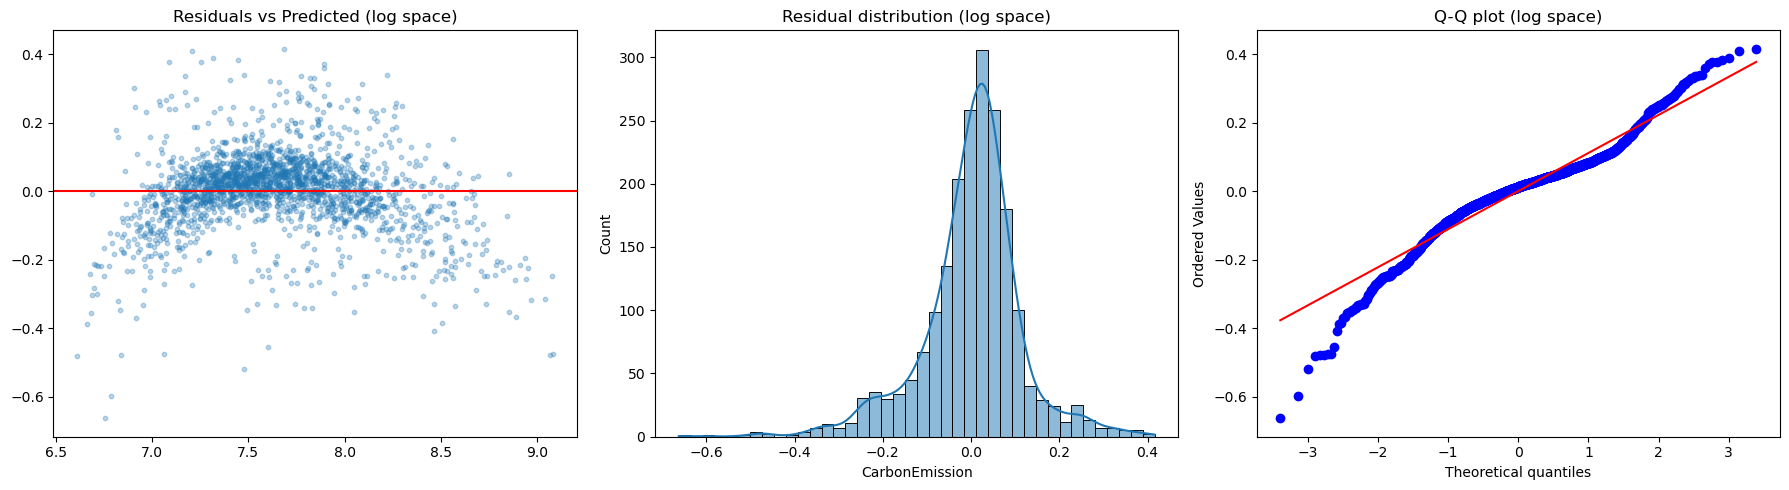

Residual skewness: -0.59
Residual kurtosis: 2.97


In [28]:
# Train on the log of the target
y_train_log = np.log(y_train)

lr_log = LinearRegression().fit(X_train_mp, y_train_log)

# Predict in log space, then convert back to original units
pred_train_log = np.exp(lr_log.predict(X_train_mp))
pred_test_log = np.exp(lr_log.predict(X_test_mp))

res_log = pd.DataFrame({
    "Train": evaluate(y_train, pred_train_log, k4),
    "Test": evaluate(y_test, pred_test_log, k4),
}).round(3)
print("=== LINEAR REGRESSION on log(target) ===")
print(res_log)

# Compare against the plain model
print("\n=== TEST COMPARISON ===")
print(pd.DataFrame({
    "Plain": res4["Test"],
    "Log-target": res_log["Test"],
}))

# Re-check residual diagnostics (in log space, where the model was fit)
resid_log = np.log(y_test) - lr_log.predict(X_test_mp)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(lr_log.predict(X_test_mp), resid_log, alpha=0.3, s=10)
axes[0].axhline(0, color="red")
axes[0].set_title("Residuals vs Predicted (log space)")
sns.histplot(resid_log, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution (log space)")
stats.probplot(resid_log, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot (log space)")
plt.tight_layout()
plt.show()

print(f"Residual skewness: {stats.skew(resid_log):.2f}")
print(f"Residual kurtosis: {stats.kurtosis(resid_log):.2f}")

<div style="border-left:6px solid #dc2626;background:rgba(220,38,38,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#dc2626;margin-bottom:6px">❌ Inference: log-transforming the target did not help</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Accuracy:</b> Test R² 0.887 and RMSE 343, worse than the plain model (0.938, 253)</li><li><b>Fixed:</b> The funnel shape is mostly gone and kurtosis improved (5.64 → 2.97)</li><li><b>Broke:</b> Residuals now form an arch and skewness flipped to −0.59</li><li><b>Reason:</b> The curvature comes from interactions (e.g. distance x fuel type), which a log cannot capture</li><li><b>Decision:</b> Keep the plain-target model as the linear baseline</li></ul></div>

In [29]:
from sklearn.linear_model import RidgeCV, LassoCV

# Alpha values to try (log-spaced from tiny to large)
alphas = np.logspace(-3, 3, 50)

# Ridge: 5-fold cross-validation picks the best alpha
ridge = RidgeCV(alphas=alphas, cv=5).fit(X_train_mp, y_train)

# Lasso: same idea (more iterations so it converges)
lasso = LassoCV(alphas=alphas, cv=5, max_iter=20000,
                random_state=42).fit(X_train_mp, y_train)

print(f"Best Ridge alpha: {ridge.alpha_:.4f}")
print(f"Best Lasso alpha: {lasso.alpha_:.4f}")

# Score all three linear models on the test set
scores = pd.DataFrame({
    "LinearReg": res4["Test"],
    "Ridge": evaluate(y_test, ridge.predict(X_test_mp), k4),
    "Lasso": evaluate(y_test, lasso.predict(X_test_mp), k4),
}).round(3)
print("\n=== TEST SCORES ===")
print(scores)

# How many features did Lasso bench (coefficient = 0)?
coefs = pd.DataFrame({
    "feature": names_m,
    "Linear": lr4.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
})
print(f"\nLasso zeroed-out features: {(coefs['Lasso'] == 0).sum()} of {k4}")
print("\n=== TOP 10 FEATURES BY |Lasso coefficient| ===")
print(coefs.reindex(coefs["Lasso"].abs().sort_values(ascending=False).index)
      .head(10).round(1).to_string(index=False))

Best Ridge alpha: 0.0222
Best Lasso alpha: 0.0687

=== TEST SCORES ===
        LinearReg    Ridge    Lasso
R2          0.938    0.938    0.938
Adj_R2      0.937    0.937    0.937
RMSE      253.475  253.474  253.426
MAE       164.942  164.941  164.881

Lasso zeroed-out features: 1 of 44

=== TOP 10 FEATURES BY |Lasso coefficient| ===
                                           feature  Linear   Ridge   Lasso
                            cat__Mobility_electric -1268.7 -1268.6 -1265.5
cat__Frequency_of_Traveling_by_Air_very frequently   661.5   661.5   661.6
          cat__Frequency_of_Traveling_by_Air_never  -644.8  -644.8  -644.3
                              cat__Mobility_petrol   611.9   612.0   613.0
                  num__Vehicle_Monthly_Distance_Km   568.3   568.3   568.7
         cat__Frequency_of_Traveling_by_Air_rarely  -466.0  -466.0  -465.4
                              cat__Mobility_hybrid  -449.5  -449.4  -446.3
            cat__Heating_Energy_Source_electricity  -430.3  -430.

<div style="border-left:6px solid #2563eb;background:rgba(37,99,235,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#2563eb;margin-bottom:6px">🔍 Inference: regularisation changes nothing here</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Alphas:</b> Ridge 0.022 and Lasso 0.069: tiny, so no strict penalty was needed</li><li><b>Scores:</b> All three models: R² 0.938, RMSE about 253.4</li><li><b>Lasso:</b> Zeroed only 1 of 44 features</li><li><b>Why:</b> 8,000 rows for 44 clean features with no overfitting leaves nothing to regularise</li><li><b>Coefficients:</b> Electric −1,269 (vs reference group), very frequent flyers +662, never-flyers −645, distance +568 per standard deviation</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 6</span><br><span style="font-size:21px;font-weight:700">Non-linear Models: Random Forest & XGBoost</span><br><span style="font-size:13px;opacity:.9">Can trees capture the interactions the linear model misses?</span></div>

In [30]:
from sklearn.ensemble import RandomForestRegressor

# 300 trees; n_jobs=-1 uses all CPU cores
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                           n_jobs=-1, random_state=42)
rf.fit(X_train_mp, y_train)

# Score on train and test
rf_res = pd.DataFrame({
    "Train": evaluate(y_train, rf.predict(X_train_mp), k4),
    "Test": evaluate(y_test, rf.predict(X_test_mp), k4),
}).round(3)
print("=== RANDOM FOREST ===")
print(rf_res)

# Compare with the best linear model
print("\n=== TEST COMPARISON ===")
print(pd.DataFrame({"LinearReg": res4["Test"], "RandomForest": rf_res["Test"]}))

# Residual quick check
rf_resid = y_test - rf.predict(X_test_mp)
print(f"\nResidual skewness: {stats.skew(rf_resid):.2f}")
print(f"Residual kurtosis: {stats.kurtosis(rf_resid):.2f}")

=== RANDOM FOREST ===
          Train     Test
R2        0.985    0.922
Adj_R2    0.985    0.920
RMSE    124.951  284.761
MAE      90.123  215.392

=== TEST COMPARISON ===
        LinearReg  RandomForest
R2          0.938         0.922
Adj_R2      0.937         0.920
RMSE      253.475       284.761
MAE       164.942       215.392

Residual skewness: 0.56
Residual kurtosis: 1.72


<div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Inference: Random Forest overfits and loses</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Test:</b> R² 0.922, RMSE 284.8, MAE 215.4 (worse than linear 253.5)</li><li><b>Overfit:</b> Train R² 0.985 vs test 0.922; train RMSE 125 vs test 285</li><li><b>Why:</b> Emissions are mostly an additive, smooth recipe; averaged independent trees approximate that poorly with 8,000 rows</li></ul></div>

In [31]:
from xgboost import XGBRegressor

# Gentle, careful relay: many small trees, low learning rate
xgb = XGBRegressor(
    n_estimators=2000,        # max number of runners
    learning_rate=0.03,       # small corrections each time
    max_depth=3,              # shallow trees (less memorizing)
    subsample=0.8,            # each tree sees 80% of rows
    colsample_bytree=0.8,     # and 80% of columns
    early_stopping_rounds=50, # stop when test-fold stops improving
    n_jobs=-1,
    random_state=42,
)

# Hold out part of TRAIN for early stopping (test set stays untouched)
Xtr, Xval, ytr, yval = train_test_split(
    X_train_mp, y_train, test_size=0.15, random_state=42
)
xgb.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
print("Trees actually used:", xgb.best_iteration + 1)

# Score on train and test
xgb_res = pd.DataFrame({
    "Train": evaluate(y_train, xgb.predict(X_train_mp), k4),
    "Test": evaluate(y_test, xgb.predict(X_test_mp), k4),
}).round(3)
print("\n=== XGBOOST ===")
print(xgb_res)

# Compare all models on the test set
print("\n=== TEST COMPARISON ===")
print(pd.DataFrame({
    "LinearReg": res4["Test"],
    "RandomForest": rf_res["Test"],
    "XGBoost": xgb_res["Test"],
}))

Trees actually used: 2000

=== XGBOOST ===
         Train     Test
R2       0.993    0.989
Adj_R2   0.993    0.989
RMSE    83.213  107.709
MAE     61.772   79.189

=== TEST COMPARISON ===
        LinearReg  RandomForest  XGBoost
R2          0.938         0.922    0.989
Adj_R2      0.937         0.920    0.989
RMSE      253.475       284.761  107.709
MAE       164.942       215.392   79.189


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: XGBoost is a big improvement</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Test:</b> R² 0.989, RMSE 107.7, MAE 79.2: less than half the linear RMSE</li><li><b>Overfit:</b> Train 0.993 vs test 0.989 is a small gap</li><li><b>Why:</b> Each boosted tree fixes the previous errors, building both the smooth trend and the interactions</li><li><b>Note:</b> It used all 2,000 allowed trees, so it was still improving slightly</li></ul></div>

In [32]:
# Same relay, more room and a slightly faster pace
xgb2 = XGBRegressor(
    n_estimators=6000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=42,
)
xgb2.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
print("Trees actually used:", xgb2.best_iteration + 1)

xgb2_res = pd.DataFrame({
    "Train": evaluate(y_train, xgb2.predict(X_train_mp), k4),
    "Test": evaluate(y_test, xgb2.predict(X_test_mp), k4),
}).round(3)
print("\n=== XGBOOST (tuned) ===")
print(xgb2_res)

print("\n=== TEST COMPARISON ===")
print(pd.DataFrame({
    "XGBoost v1": xgb_res["Test"],
    "XGBoost v2": xgb2_res["Test"],
}))

Trees actually used: 2161

=== XGBOOST (tuned) ===
         Train     Test
R2       0.997    0.989
Adj_R2   0.997    0.989
RMSE    57.009  106.846
MAE     38.479   78.891

=== TEST COMPARISON ===
        XGBoost v1  XGBoost v2
R2           0.989       0.989
Adj_R2       0.989       0.989
RMSE       107.709     106.846
MAE         79.189      78.891


<div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Inference: more trees did not help</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Result:</b> RMSE 106.8 vs 107.7: under 1% better</li><li><b>Overfit:</b> Train RMSE fell to 57 while test stayed at about 107, so the gap widened (25 → 50)</li><li><b>Decision:</b> Extra complexity bought memorisation, not accuracy</li></ul></div>

In [33]:
# Four "less memorizing" settings to compare
configs = {
    "v1 (baseline)":  dict(max_depth=3, learning_rate=0.03),
    "shallow+rule":   dict(max_depth=3, learning_rate=0.03, min_child_weight=10),
    "L2 penalty":     dict(max_depth=3, learning_rate=0.03, reg_lambda=20),
    "L1+L2+rule":     dict(max_depth=4, learning_rate=0.03, min_child_weight=10,
                           reg_lambda=20, reg_alpha=5),
}

rows = []
for name, params in configs.items():
    m = XGBRegressor(n_estimators=4000, subsample=0.8, colsample_bytree=0.8,
                     early_stopping_rounds=100, n_jobs=-1, random_state=42,
                     **params)
    m.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
    rmse = lambda X, y: np.sqrt(mean_squared_error(y, m.predict(X)))
    rows.append({"model": name, "trees": m.best_iteration + 1,
                 "Train_RMSE": rmse(Xtr, ytr), "Val_RMSE": rmse(Xval, yval),
                 "Test_RMSE": rmse(X_test_mp, y_test)})

out = pd.DataFrame(rows).round(1)
out["Gap (Val-Train)"] = (out["Val_RMSE"] - out["Train_RMSE"]).round(1)
print(out.to_string(index=False))

        model  trees  Train_RMSE  Val_RMSE  Test_RMSE  Gap (Val-Train)
v1 (baseline)   3999        62.5      98.5      100.0             36.0
 shallow+rule   3999        63.2      97.8       99.7             34.6
   L2 penalty   3987        66.1      99.2       99.7             33.1
   L1+L2+rule   3670        47.7     105.7      105.4             58.0


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: regularised XGBoost settings compared</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Winner:</b> `shallow+rule` (min_child_weight = 10): validation RMSE 97.8, test RMSE 99.7</li><li><b>Tie:</b> Baseline and L2 penalty are within about 1 RMSE unit: noise</li><li><b>Worse:</b> L1 + L2 + depth 4 reached validation RMSE 105.7 and the largest gap (58)</li><li><b>Selection:</b> Chosen on validation, not on test, so the test score stays honest</li><li><b>Lesson:</b> A train-test gap never reaches zero; a gap of about 35 on an error of about 100 is normal</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 7</span><br><span style="font-size:21px;font-weight:700">Feature Importance & Final Model</span><br><span style="font-size:13px;opacity:.9">What drives emissions, according to the best model</span></div>

=== FINAL XGBOOST ===
         Train    Test
R2       0.995   0.990
Adj_R2   0.995   0.990
RMSE    69.496  99.742
MAE     51.587  73.556

=== TOP 15 FEATURES (permutation importance) ===
                                           feature  Perm_Importance  Built_in
                  num__Vehicle_Monthly_Distance_Km          868.084     0.068
cat__Frequency_of_Traveling_by_Air_very frequently          334.883     0.198
                            cat__Mobility_electric          311.759     0.190
          cat__Frequency_of_Traveling_by_Air_never          264.060     0.091
                           num__Waste_Volume_Index          232.417     0.028
                 num__How_Many_New_Clothes_Monthly          201.123     0.017
                              cat__Body_Type_obese          178.280     0.027
         cat__Frequency_of_Traveling_by_Air_rarely          171.754     0.065
                                     cat__Sex_male          171.541     0.030
            cat__Heating_Energy_S

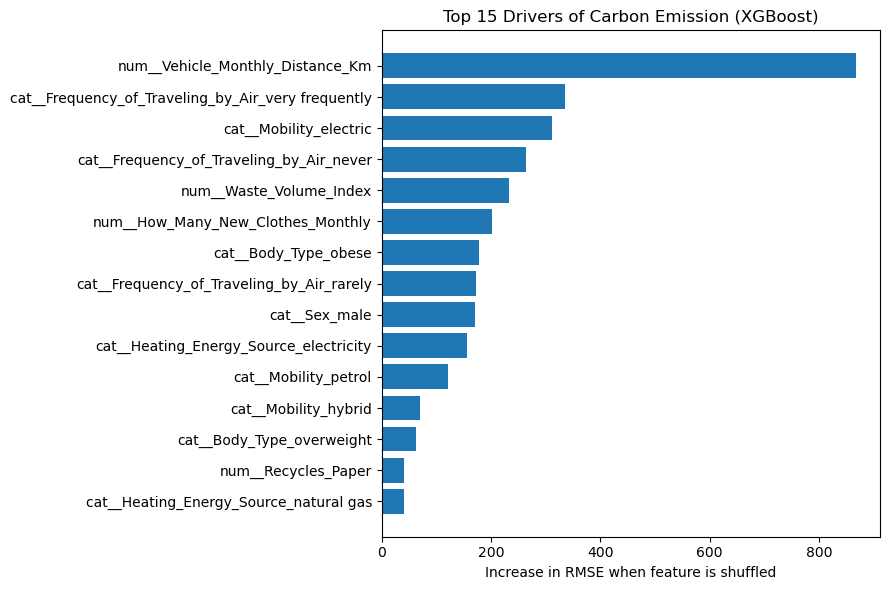


=== BOTTOM 8 (least useful) ===
                              feature  Perm_Importance  Built_in
           cat__Mobility_walk/bicycle            1.022     0.001
                     num__Cooks_Stove            0.764     0.001
    cat__How_Often_Shower_twice a day            0.696     0.000
cat__How_Often_Shower_less frequently            0.378     0.001
                 num__Cooks_Microwave            0.236     0.000
            cat__Waste_Bag_Size_large            0.135     0.000
            cat__Waste_Bag_Size_small            0.061     0.000
           cat__Waste_Bag_Size_medium           -0.003     0.000


In [34]:
from sklearn.inspection import permutation_importance

# Final model = the winning setting
final_xgb = XGBRegressor(n_estimators=4000, learning_rate=0.03, max_depth=3,
                         min_child_weight=10, subsample=0.8,
                         colsample_bytree=0.8, early_stopping_rounds=100,
                         n_jobs=-1, random_state=42)
final_xgb.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)

# Final scores on the test set
final_res = pd.DataFrame({
    "Train": evaluate(y_train, final_xgb.predict(X_train_mp), k4),
    "Test": evaluate(y_test, final_xgb.predict(X_test_mp), k4),
}).round(3)
print("=== FINAL XGBOOST ===")
print(final_res)

# Permutation importance on the TEST set (shuffle each column 5 times)
perm = permutation_importance(final_xgb, X_test_mp, y_test, n_repeats=5,
                              random_state=42, n_jobs=-1,
                              scoring="neg_root_mean_squared_error")
imp = pd.DataFrame({
    "feature": names_m,
    "Perm_Importance": perm.importances_mean,   # RMSE increase when shuffled
    "Built_in": final_xgb.feature_importances_,
}).sort_values("Perm_Importance", ascending=False)

print("\n=== TOP 15 FEATURES (permutation importance) ===")
print(imp.head(15).round(3).to_string(index=False))

# Bar chart of the top 15
top = imp.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["Perm_Importance"])
plt.xlabel("Increase in RMSE when feature is shuffled")
plt.title("Top 15 Drivers of Carbon Emission (XGBoost)")
plt.tight_layout()
plt.show()

# Features that add almost nothing
print("\n=== BOTTOM 8 (least useful) ===")
print(imp.tail(8).round(3).to_string(index=False))

<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: final model performance</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Test:</b> R² 0.990, RMSE 99.7, MAE 73.6 (about 3% of mean emission)</li><li><b>Gap:</b> Train RMSE 69.5 vs test 99.7: the smallest gap of any tree model</li></ul></div>

<div style="border-left:6px solid #7c3aed;background:rgba(124,58,237,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#7c3aed;margin-bottom:6px">💡 Inference: top drivers (permutation importance)</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>1. Distance:</b> RMSE rises by 868 when shuffled, by far the biggest</li><li><b>2-4. Air travel and vehicle:</b> Very-frequent flying 335, electric vehicle 312, never flying 264, rarely flying 172</li><li><b>5-7:</b> Waste volume 232, new clothes 201, obese body type 178</li><li><b>Near zero:</b> Shower habits, stove, microwave and waste bag size add about 0-1 each</li><li><b>Reading it:</b> Correlated features share credit (waste index and bag size; air and mobility dummies), so read the groups. Built-in importance is biased toward few-category features, so trust permutation importance. These are predictive patterns, not proof of cause</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 8</span><br><span style="font-size:21px;font-weight:700">Sustainability What-If Analysis</span><br><span style="font-size:13px;opacity:.9">Change one habit for real people in the test set and re-predict</span></div>

In [35]:
# Work on the TEST rows in their readable (unprocessed) form
base = X_test_m.copy()
base_pred = final_xgb.predict(preprocessor_m.transform(base))

def what_if(change_fn, mask=None):
    """Apply a change to the people it applies to, return avg predicted drop."""
    mod = base.copy()
    idx = mask if mask is not None else pd.Series(True, index=base.index)
    mod = change_fn(mod, idx)
    new_pred = final_xgb.predict(preprocessor_m.transform(mod))
    diff = (base_pred - new_pred)[idx.values]
    return diff.mean(), idx.sum()

scenarios = {}

# 1) Petrol/diesel/lpg drivers switch to electric
fossil = base["Mobility"].isin(["petrol", "diesel", "lpg"])
scenarios["Fossil car -> electric"] = what_if(
    lambda d, i: d.assign(Mobility=d["Mobility"].where(~i, "electric")), fossil)

# 2) Cut driving distance by 30% (private drivers)
drivers = ~base["Mobility"].isin(["public", "walk/bicycle"])
scenarios["Drive 30% less (drivers)"] = what_if(
    lambda d, i: d.assign(Vehicle_Monthly_Distance_Km=
        d["Vehicle_Monthly_Distance_Km"].where(~i, d["Vehicle_Monthly_Distance_Km"] * 0.7)),
    drivers)

# 3) Very frequent flyers -> rarely
vf = base["Frequency_of_Traveling_by_Air"] == "very frequently"
scenarios["Very frequent flyers -> rarely"] = what_if(
    lambda d, i: d.assign(Frequency_of_Traveling_by_Air=
        d["Frequency_of_Traveling_by_Air"].where(~i, "rarely")), vf)

# 4) Coal/wood heating -> electricity
dirty = base["Heating_Energy_Source"].isin(["coal", "wood"])
scenarios["Coal/wood heat -> electricity"] = what_if(
    lambda d, i: d.assign(Heating_Energy_Source=
        d["Heating_Energy_Source"].where(~i, "electricity")), dirty)

# 5) Recycle paper (people who don't)
nopaper = base["Recycles_Paper"] == 0
scenarios["Start recycling paper"] = what_if(
    lambda d, i: d.assign(Recycles_Paper=
        d["Recycles_Paper"].where(~i, 1)), nopaper)

# 6) Buy 10 fewer new clothes per month (people buying >10)
clothes = base["How_Many_New_Clothes_Monthly"] > 10
scenarios["Buy 10 fewer clothes/month"] = what_if(
    lambda d, i: d.assign(How_Many_New_Clothes_Monthly=
        d["How_Many_New_Clothes_Monthly"].where(~i,
            d["How_Many_New_Clothes_Monthly"] - 10)), clothes)

# 7) Smaller waste bags (large/extra large -> medium)
bigbag = base["Waste_Bag_Size"].isin(["large", "extra large"])
scenarios["Large bags -> medium"] = what_if(
    lambda d, i: d.assign(Waste_Bag_Size=
        d["Waste_Bag_Size"].where(~i, "medium")), bigbag)

rec = pd.DataFrame(scenarios, index=["Avg_drop", "People"]).T
rec["Avg_drop"] = rec["Avg_drop"].round(0)
rec["People"] = rec["People"].astype(int)
rec["Pct_of_avg_emission"] = (rec["Avg_drop"] / y_test.mean() * 100).round(1)
print(rec.sort_values("Avg_drop", ascending=False).to_string())

                                Avg_drop  People  Pct_of_avg_emission
Fossil car -> electric            1507.0     390                 65.8
Very frequent flyers -> rarely    1105.0     532                 48.2
Coal/wood heat -> electricity      329.0    1010                 14.4
Drive 30% less (drivers)           322.0     651                 14.1
Start recycling paper              141.0     990                  6.2
Buy 10 fewer clothes/month         138.0    1578                  6.0
Large bags -> medium                 3.0     984                  0.1


<div style="border-left:6px solid #7c3aed;background:rgba(124,58,237,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#7c3aed;margin-bottom:6px">💡 Inference: ranked habit changes</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>1. Fossil car → electric:</b> −1,507 per person (65.8% of mean), 390 people</li><li><b>2. Very frequent flyers → rarely:</b> −1,105 (48.2%), 532 people</li><li><b>3. Coal/wood heat → electricity:</b> −329 (14.4%), 1,010 people</li><li><b>4. Drive 30% less:</b> −322 (14.1%), 651 people</li><li><b>5-6. Recycle paper / 10 fewer clothes:</b> −141 (6.2%) and −138 (6.0%)</li><li><b>7. Large bags → medium:</b> −3 (0.1%): unreliable, because `Waste_Volume_Index` was not recalculated in the scenario</li><li><b>Total impact:</b> Car switch and flying less tie at about 588,000 (people x drop); heating is about 332,000</li></ul></div>

<div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Limitations of the what-if analysis</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Not causal:</b> Model predictions only; a real person may see a different change</li><li><b>Not additive:</b> Savings from several changes will not simply add up because of interactions</li><li><b>Unit:</b> The dataset does not state the unit of `CarbonEmission`</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 9</span><br><span style="font-size:21px;font-weight:700">Optional Improvements</span><br><span style="font-size:13px;opacity:.9">A simpler model and an interaction-aware linear model</span></div>

In [37]:
# Columns whose permutation importance was ~0 (from the bottom-8 table)
drop_small = ["How_Often_Shower", "Cooks_Stove", "Cooks_Microwave",
              "Waste_Bag_Size"]  # Waste_Volume_Index already holds bag size

X_train_s = X_train_m.drop(columns=drop_small)
X_test_s = X_test_m.drop(columns=drop_small)

# Rebuild the preprocessor on the smaller set
num_s = X_train_s.select_dtypes(include="number").columns.tolist()
cat_s = X_train_s.select_dtypes(include="object").columns.tolist()
preprocessor_s = ColumnTransformer([
    ("num", num_pipe, num_s),
    ("cat", cat_pipe, cat_s),
])
X_train_sp = preprocessor_s.fit_transform(X_train_s)
X_test_sp = preprocessor_s.transform(X_test_s)
print("Columns: before", X_train_mp.shape[1], "-> after", X_train_sp.shape[1])

# Same split as before (same random_state) for early stopping
Xtr_s, Xval_s, ytr_s, yval_s = train_test_split(
    X_train_sp, y_train, test_size=0.15, random_state=42)

# Same winning settings as final_xgb
xgb_s = XGBRegressor(n_estimators=4000, learning_rate=0.03, max_depth=3,
                     min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                     early_stopping_rounds=100, n_jobs=-1, random_state=42)
xgb_s.fit(Xtr_s, ytr_s, eval_set=[(Xval_s, yval_s)], verbose=False)

k_s = X_train_sp.shape[1]
simple_res = pd.DataFrame({
    "Train": evaluate(y_train, xgb_s.predict(X_train_sp), k_s),
    "Test": evaluate(y_test, xgb_s.predict(X_test_sp), k_s),
}).round(3)
print("\n=== SIMPLER XGBOOST ===")
print(simple_res)

print("\n=== TEST COMPARISON ===")
print(pd.DataFrame({"Full XGBoost": final_res["Test"],
                    "Simpler XGBoost": simple_res["Test"]}))

Columns: before 44 -> after 36

=== SIMPLER XGBOOST ===
         Train     Test
R2       0.995    0.990
Adj_R2   0.995    0.990
RMSE    72.466  101.792
MAE     54.076   75.927

=== TEST COMPARISON ===
        Full XGBoost  Simpler XGBoost
R2             0.990            0.990
Adj_R2         0.990            0.990
RMSE          99.742          101.792
MAE           73.556           75.927


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: simpler XGBoost is almost free</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Columns:</b> 44 → 36 (dropped showers, stove, microwave, waste bag size)</li><li><b>Test:</b> RMSE 101.8 vs 99.7 (about 2% worse); R² unchanged at 0.990</li><li><b>Meaning:</b> Fewer survey questions to collect for almost the same accuracy. The 2-unit difference may be noise</li></ul></div>

In [38]:
# Build one "distance x travel type" column per Mobility category
mob_levels = sorted(X_train_m["Mobility"].unique())

def add_interactions(d):
    d = d.copy()
    for m in mob_levels:
        name = "Dist_x_" + m.replace("/", "_")
        d[name] = d["Vehicle_Monthly_Distance_Km"] * (d["Mobility"] == m).astype(int)
    # Plain distance = sum of the new columns, so drop it (avoids duplicates)
    return d.drop(columns=["Vehicle_Monthly_Distance_Km"])

X_train_i = add_interactions(X_train_m)
X_test_i = add_interactions(X_test_m)

# Rebuild preprocessor and fit
num_i = X_train_i.select_dtypes(include="number").columns.tolist()
cat_i = X_train_i.select_dtypes(include="object").columns.tolist()
preprocessor_i = ColumnTransformer([
    ("num", num_pipe, num_i),
    ("cat", cat_pipe, cat_i),
])
X_train_ip = preprocessor_i.fit_transform(X_train_i)
X_test_ip = preprocessor_i.transform(X_test_i)
names_i = preprocessor_i.get_feature_names_out()

lr_i = LinearRegression().fit(X_train_ip, y_train)
k_i = X_train_ip.shape[1]
inter_res = pd.DataFrame({
    "Train": evaluate(y_train, lr_i.predict(X_train_ip), k_i),
    "Test": evaluate(y_test, lr_i.predict(X_test_ip), k_i),
}).round(3)
print("=== LINEAR + INTERACTIONS ===")
print(inter_res)

print("\n=== TEST COMPARISON ===")
print(pd.DataFrame({"Linear (before)": res4["Test"],
                    "Linear + interactions": inter_res["Test"],
                    "XGBoost (final)": final_res["Test"]}))

# Emission added per extra 1,000 km, for each travel type
scale = preprocessor_i.named_transformers_["num"].named_steps["scale"].scale_
coef = pd.Series(lr_i.coef_[:len(num_i)], index=num_i)
per_1000km = (coef * 1000 / scale)[[c for c in num_i if c.startswith("Dist_x_")]]
print("\n=== EXTRA EMISSION PER +1,000 KM ===")
print(per_1000km.round(0).sort_values(ascending=False))

# Did the smile / heavy tails improve?
resid_i = y_test - lr_i.predict(X_test_ip)
print(f"\nResidual skewness: {stats.skew(resid_i):.2f}  (before: 0.31)")
print(f"Residual kurtosis: {stats.kurtosis(resid_i):.2f}  (before: 5.64)")

=== LINEAR + INTERACTIONS ===
          Train     Test
R2        0.982    0.982
Adj_R2    0.982    0.981
RMSE    137.613  138.133
MAE      98.802   98.961

=== TEST COMPARISON ===
        Linear (before)  Linear + interactions  XGBoost (final)
R2                0.938                  0.982            0.990
Adj_R2            0.937                  0.981            0.990
RMSE            253.475                138.133           99.742
MAE             164.942                 98.961           73.556

=== EXTRA EMISSION PER +1,000 KM ===
Dist_x_petrol          372.0
Dist_x_lpg             273.0
Dist_x_diesel          246.0
Dist_x_hybrid          164.0
Dist_x_public           64.0
Dist_x_electric          0.0
Dist_x_walk_bicycle    -65.0
dtype: float64

Residual skewness: 0.54  (before: 0.31)
Residual kurtosis: 4.56  (before: 5.64)


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: Distance x Fuel interactions rescue the linear model</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Scores:</b> R² 0.938 → 0.982; RMSE 253.5 → 138.1; MAE 164.9 → 99.0</li><li><b>No overfit:</b> Train RMSE 137.6 vs test 138.1</li><li><b>Extra emission per +1,000 km:</b> Petrol 372, LPG 273, diesel 246, hybrid 164, public 64, electric 0, walk/bicycle about 0 (the −65 is noise from a narrow distance range)</li><li><b>Residuals:</b> Kurtosis fell 5.64 → 4.56, but some curvature remains (skewness 0.54), so other interactions exist that XGBoost finds automatically</li><li><b>Use:</b> XGBoost for prediction; the interaction linear model for explanation</li></ul></div>

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 10</span><br><span style="font-size:21px;font-weight:700">Save the Final Pipeline</span><br><span style="font-size:13px;opacity:.9">Bundle preprocessing and model for reuse</span></div>

In [39]:
import joblib
from sklearn.pipeline import Pipeline

# Bundle preprocessing + model into one object (full XGBoost)
final_pipeline = Pipeline([
    ("prep", preprocessor_m),
    ("model", final_xgb),
])

# Save to disk
joblib.dump(final_pipeline, "carbon_emission_xgb.joblib")

# Reload and test on raw (unprocessed) test rows
loaded = joblib.load("carbon_emission_xgb.joblib")
pred_check = loaded.predict(X_test_m)

# Predictions must match the earlier ones exactly
print("Max difference vs earlier predictions:",
      np.abs(pred_check - final_xgb.predict(X_test_mp)).max())
print("Test RMSE from reloaded pipeline:",
      round(np.sqrt(mean_squared_error(y_test, pred_check)), 1))

# Example: predict for the first 3 people
print("\nPredicted:", pred_check[:3].round(0))
print("Actual:   ", y_test.values[:3])

Max difference vs earlier predictions: 0.0
Test RMSE from reloaded pipeline: 99.7

Predicted: [ 982. 1634. 2259.]
Actual:    [ 978 1608 2236]


<div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Inference: saved pipeline reproduces results exactly</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Check:</b> Maximum difference vs earlier predictions is 0.0; reloaded test RMSE is 99.7</li><li><b>Sample:</b> Predicted 982 / 1634 / 2259 vs actual 978 / 1608 / 2236 (within about 1-3%)</li><li><b>Usage:</b> New data must have the same columns as `X_test_m`, including the `Mobility` column</li></ul></div>

In [40]:
# import joblib
# model = joblib.load("carbon_emission_xgb.joblib")
# # new_data must have the same columns as X_test_m (including "Mobility")
# prediction = model.predict(new_data)

<div style="background:linear-gradient(90deg,#0f766e,#2563eb);color:#fff;padding:14px 20px;border-radius:8px;margin-top:18px"><span style="font-size:13px;opacity:.85">SECTION 11</span><br><span style="font-size:21px;font-weight:700">Results, Recommendations & Conclusion</span><br><span style="font-size:13px;opacity:.9">Final model comparison and what to do with it</span></div>

### Model comparison (test set)
| Model | R² | RMSE | MAE | Verdict |
|---|---|---|---|---|
| Linear Regression (clean features) | 0.938 | 253.5 | 164.9 | Strong baseline, assumptions fail, curved residuals |
| Linear on log(target) | 0.887 | 343.0 | 197.5 | Fixed funnel, hurt accuracy |
| Ridge / Lasso | 0.938 | 253.4 | 164.9 | Same as linear; no overfitting to fix |
| Random Forest | 0.922 | 284.8 | 215.4 | Overfit |
| Linear + Distance x Fuel | 0.982 | 138.1 | 99.0 | Best explainable model, no overfit |
| Simpler XGBoost (36 columns) | 0.990 | 101.8 | 75.9 | Almost as accurate, fewer inputs |
| **XGBoost (final, 44 columns)** | **0.990** | **99.7** | **73.6** | **Best accuracy** |

<div style="border-left:6px solid #7c3aed;background:rgba(124,58,237,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#7c3aed;margin-bottom:6px">💡 Key conclusions</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Drivers:</b> Vehicle distance, vehicle fuel type and air travel explain most emissions; heating source, waste volume, clothes and body type add smaller effects</li><li><b>Interactions matter:</b> A kilometre in a petrol car adds about 372 vs about 0 in an electric car. Capturing this took the linear R² from 0.938 to 0.982</li><li><b>Complexity is not automatically better:</b> Random Forest lost to a plain linear model; boosting won</li><li><b>Weak factors:</b> Diet, showers, energy efficiency, social activity and cooking appliances barely change predicted emissions in this dataset</li></ul></div><div style="border-left:6px solid #16a34a;background:rgba(22,163,74,.08);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#16a34a;margin-bottom:6px">✅ Recommendations</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Electrify vehicles:</b> the largest per-person drop</li><li><b>Reduce frequent flying:</b> second largest, nearly equal total impact</li><li><b>Replace coal/wood heating with electricity:</b> moderate per person but reaches the most people</li><li><b>Cut driving distance:</b> distance is the number-one model driver</li><li><b>Recycle paper and buy fewer clothes:</b> small, low-cost wins</li><li><b>Do not prioritise</b> shower habits, cooking appliances or bag size</li></ul></div><div style="border-left:6px solid #d97706;background:rgba(217,119,6,.10);padding:12px 18px;border-radius:6px;margin:6px 0"><div style="font-size:15px;font-weight:700;color:#d97706;margin-bottom:6px">⚠️ Limitations & next steps</div><ul style="margin:0;padding-left:20px;line-height:1.6"><li><b>Limitations:</b> What-if results are predictions, not causal effects; changes will not add up; the target unit is not stated; the data may be synthetic or survey-based, since the features look uniformly distributed</li><li><b>Next steps:</b> SHAP explanations per person; cross-validated tuning; more interaction features (air travel x other habits); a small web app using the saved pipeline</li></ul></div>